# USD/THB Univariate: Rolling one-step-ahead forecasting

Compare seven models using a **fixed-length rolling training window of 501 actual observations**. XGBoost and neural models are refitted from scratch at every forecast origin. This is rolling re-estimation, not fixed-parameter forecasting.

| Stage | Observed dates | Count |
|---|---|---:|
| Initial Train | 2 Jan 2024–31 Dec 2025 | 501 |
| Validation | 2 Jan–29 May 2026 | 103 |
| Test | 1 Jun–30 Sep 2026 | 85 |

Use Validation RMSE to choose each model's hyperparameters and the overall model. Keep settings fixed during Test. Previous actuals may enter the next training window once observed; the current target cannot. These calendar periods are design choices, not proven optimal boundaries. Earlier 2026 results have been inspected, so Test is a revised evaluation rather than an untouched holdout.

Every model uses USD/THB history only. All models forecast the same next observed exchange-rate level in THB per USD.

Run the installation cell, configuration and preparation cells, then each model cell in order. The method is explained before every model, and the hyperparameter specification follows its cell. All tables, plots, predictions and audits stay in memory and are displayed here. **No result files or checkpoints are written.** Saving this notebook in VS Code can preserve its displayed outputs.

**Author: Chetsada Phummee.** Academic project, portfolio edition. Saved model outputs are retained from the original run; this public edition removes personal Drive file IDs and uses the embedded supplied-data snapshot by default. See the repository README for data provenance and limitations.


In [1]:
# Run once in a fresh Colab runtime. If asked to restart, restart before imports.
%pip -q install numpy pandas torch "xgboost>=2.0,<4" openpyxl requests scikit-learn matplotlib tqdm "chronos-forecasting>=2.0,<3" "transformers>=4.41,<5" "timesfm[torch]==2.0.2"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os,sys,json,random,gc,hashlib,io
if sys.platform=='darwin':os.environ.setdefault('OMP_NUM_THREADS','1')
from xgboost import XGBRegressor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tqdm.auto import tqdm
import torch
from torch import nn
from torch.utils.data import TensorDataset,DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error,mean_squared_error
from threadpoolctl import threadpool_limits

SEED=42
ESTIMATION_WINDOW=501
VALIDATION_FORECASTS=103
TEST_FORECASTS=85
BATCH_SIZE=64
CONTEXT_OPTIONS=[64,128]
FOUNDATION_BATCH=16
RUN_MODE="full"  # "smoke": two origins per split, one small candidate, one neural epoch
RUN_FOUNDATION_MODELS=True
FORECAST_DAYS=5
DATA_MODE="snapshot"  # snapshot | drive_link | path | upload
DATE_COL="Date"
PRICE_COL="USD_THB (THB per USD)"
CHRONOS_ID="amazon/chronos-bolt-small"
TIMESFM_ID="google/timesfm-2.5-200m-pytorch"
CHRONOS_REVISION="772f3d25d38aec6d914c8949dab4462e2d46f5d8"
TIMESFM_REVISION="1d952420fba87f3c6dee4f240de0f1a0fbc790e3"
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
CPU_THREADS=1 if sys.platform=='darwin' else 2
if sys.platform=='darwin' and DEVICE.type=='cpu':
    torch.set_num_threads(CPU_THREADS)
    _openmp_limit=threadpool_limits(limits=CPU_THREADS,user_api='openmp')

def set_seed(seed=SEED):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic=True
    torch.backends.cudnn.benchmark=False
set_seed()
IS_MULTIVARIATE=False
RUN_FUTURE_FORECASTS=True
DRIVE_FILE_ID=''  # Optional: your own workbook ID
SHEET='ARIMA_Data'
LOCAL_XLSX='YOUR_USD_THB.xlsx'
FEATURE_COLS=['USD_THB (THB per USD)']
print('Device:',DEVICE,'| Python:',sys.version.split()[0],'| torch:',torch.__version__)
if DEVICE.type=='cuda':print('GPU:',torch.cuda.get_device_name(0))

Device: cpu | Python: 3.11.15 | torch: 2.14.1


## Data preparation

Default `DATA_MODE="snapshot"` uses the embedded copy of the supplied workbook, so no upload or download is needed. `drive_link` reads the linked workbook into memory; `path` reads an existing XLSX; `upload` accepts XLSX bytes through the Colab web interface. No downloaded data file is saved by this code.

Validate positive, finite USD/THB levels and chronological, unique dates. Keep only records from 2024 onward before creating any training window. Do not fill weekends or source holidays.

In [3]:
SNAPSHOT_RECORDS = [["2012-01-03",31.29],["2012-01-04",31.5],["2012-01-05",31.62],["2012-01-06",31.7],["2012-01-09",31.78],["2012-01-10",31.62],["2012-01-11",31.75],["2012-01-12",31.76],["2012-01-13",31.81],["2012-01-17",31.76],["2012-01-18",31.74],["2012-01-19",31.62],["2012-01-20",31.5],["2012-01-23",31.35],["2012-01-24",31.36],["2012-01-25",31.57],["2012-01-26",31.23],["2012-01-27",31.05],["2012-01-30",31.14],["2012-01-31",30.97],["2012-02-01",30.93],["2012-02-02",30.87],["2012-02-03",30.88],["2012-02-06",30.93],["2012-02-07",30.85],["2012-02-08",30.76],["2012-02-09",30.72],["2012-02-10",30.84],["2012-02-13",30.72],["2012-02-14",30.83],["2012-02-15",30.77],["2012-02-16",30.82],["2012-02-17",30.81],["2012-02-21",30.68],["2012-02-22",30.54],["2012-02-23",30.29],["2012-02-24",30.31],["2012-02-27",30.39],["2012-02-28",30.3],["2012-02-29",30.46],["2012-03-01",30.5],["2012-03-02",30.58],["2012-03-05",30.66],["2012-03-06",30.84],["2012-03-07",30.7],["2012-03-08",30.56],["2012-03-09",30.56],["2012-03-12",30.63],["2012-03-13",30.58],["2012-03-14",30.79],["2012-03-15",30.72],["2012-03-16",30.72],["2012-03-19",30.69],["2012-03-20",30.77],["2012-03-21",30.76],["2012-03-22",30.8],["2012-03-23",30.71],["2012-03-26",30.68],["2012-03-27",30.71],["2012-03-28",30.79],["2012-03-29",30.91],["2012-03-30",30.82],["2012-04-02",30.81],["2012-04-03",30.8],["2012-04-04",31.01],["2012-04-05",30.97],["2012-04-06",30.97],["2012-04-09",30.93],["2012-04-10",30.98],["2012-04-11",30.87],["2012-04-12",30.74],["2012-04-13",30.73],["2012-04-16",30.77],["2012-04-17",30.79],["2012-04-18",30.86],["2012-04-19",30.87],["2012-04-20",30.88],["2012-04-23",31.0],["2012-04-24",30.91],["2012-04-25",30.92],["2012-04-26",30.82],["2012-04-27",30.72],["2012-04-30",30.74],["2012-05-01",30.7],["2012-05-02",30.85],["2012-05-03",30.95],["2012-05-04",30.92],["2012-05-07",30.99],["2012-05-08",31.0],["2012-05-09",31.06],["2012-05-10",31.11],["2012-05-11",31.17],["2012-05-14",31.35],["2012-05-15",31.33],["2012-05-16",31.36],["2012-05-17",31.32],["2012-05-18",31.31],["2012-05-21",31.35],["2012-05-22",31.36],["2012-05-23",31.56],["2012-05-24",31.53],["2012-05-25",31.64],["2012-05-29",31.73],["2012-05-30",31.85],["2012-05-31",31.83],["2012-06-01",31.62],["2012-06-04",31.43],["2012-06-05",31.56],["2012-06-06",31.47],["2012-06-07",31.7],["2012-06-08",31.61],["2012-06-11",31.62],["2012-06-12",31.54],["2012-06-13",31.5],["2012-06-14",31.51],["2012-06-15",31.45],["2012-06-18",31.44],["2012-06-19",31.38],["2012-06-20",31.53],["2012-06-21",31.78],["2012-06-22",31.79],["2012-06-25",31.83],["2012-06-26",31.87],["2012-06-27",31.86],["2012-06-28",31.87],["2012-06-29",31.56],["2012-07-02",31.54],["2012-07-03",31.37],["2012-07-05",31.55],["2012-07-06",31.7],["2012-07-09",31.72],["2012-07-10",31.68],["2012-07-11",31.7],["2012-07-12",31.78],["2012-07-13",31.58],["2012-07-16",31.57],["2012-07-17",31.66],["2012-07-18",31.7],["2012-07-19",31.55],["2012-07-20",31.65],["2012-07-23",31.72],["2012-07-24",31.76],["2012-07-25",31.62],["2012-07-26",31.56],["2012-07-27",31.52],["2012-07-30",31.56],["2012-07-31",31.49],["2012-08-01",31.55],["2012-08-02",31.59],["2012-08-03",31.48],["2012-08-06",31.44],["2012-08-07",31.45],["2012-08-08",31.46],["2012-08-09",31.45],["2012-08-10",31.43],["2012-08-13",31.43],["2012-08-14",31.4],["2012-08-15",31.49],["2012-08-16",31.45],["2012-08-17",31.47],["2012-08-20",31.48],["2012-08-21",31.39],["2012-08-22",31.38],["2012-08-23",31.14],["2012-08-24",31.17],["2012-08-27",31.25],["2012-08-28",31.29],["2012-08-29",31.32],["2012-08-30",31.38],["2012-08-31",31.24],["2012-09-04",31.2],["2012-09-05",31.23],["2012-09-06",31.17],["2012-09-07",31.04],["2012-09-10",31.04],["2012-09-11",31.03],["2012-09-12",30.99],["2012-09-13",30.99],["2012-09-14",30.74],["2012-09-17",30.8],["2012-09-18",30.79],["2012-09-19",30.79],["2012-09-20",30.85],["2012-09-21",30.77],["2012-09-24",30.92],["2012-09-25",30.88],["2012-09-26",31.01],["2012-09-27",30.88],["2012-09-28",30.82],["2012-10-01",30.73],["2012-10-02",30.67],["2012-10-03",30.67],["2012-10-04",30.55],["2012-10-05",30.55],["2012-10-09",30.68],["2012-10-10",30.7],["2012-10-11",30.68],["2012-10-12",30.69],["2012-10-15",30.73],["2012-10-16",30.66],["2012-10-17",30.59],["2012-10-18",30.62],["2012-10-19",30.73],["2012-10-22",30.7],["2012-10-23",30.76],["2012-10-24",30.72],["2012-10-25",30.67],["2012-10-26",30.69],["2012-10-29",30.73],["2012-10-30",30.68],["2012-10-31",30.68],["2012-11-01",30.71],["2012-11-02",30.76],["2012-11-05",30.81],["2012-11-06",30.74],["2012-11-07",30.71],["2012-11-08",30.67],["2012-11-09",30.62],["2012-11-13",30.65],["2012-11-14",30.67],["2012-11-15",30.71],["2012-11-16",30.73],["2012-11-19",30.66],["2012-11-20",30.67],["2012-11-21",30.69],["2012-11-23",30.67],["2012-11-26",30.67],["2012-11-27",30.65],["2012-11-28",30.71],["2012-11-29",30.69],["2012-11-30",30.7],["2012-12-03",30.64],["2012-12-04",30.66],["2012-12-05",30.67],["2012-12-06",30.65],["2012-12-07",30.63],["2012-12-10",30.64],["2012-12-11",30.61],["2012-12-12",30.59],["2012-12-13",30.61],["2012-12-14",30.58],["2012-12-17",30.58],["2012-12-18",30.59],["2012-12-19",30.59],["2012-12-20",30.61],["2012-12-21",30.59],["2012-12-24",30.6],["2012-12-26",30.64],["2012-12-27",30.65],["2012-12-28",30.59],["2012-12-31",30.59],["2013-01-02",30.32],["2013-01-03",30.33],["2013-01-04",30.48],["2013-01-07",30.46],["2013-01-08",30.41],["2013-01-09",30.36],["2013-01-10",30.25],["2013-01-11",30.28],["2013-01-14",30.23],["2013-01-15",29.94],["2013-01-16",29.8],["2013-01-17",29.78],["2013-01-18",29.71],["2013-01-22",29.71],["2013-01-23",29.79],["2013-01-24",29.81],["2013-01-25",29.96],["2013-01-28",29.93],["2013-01-29",29.76],["2013-01-30",29.7],["2013-01-31",29.85],["2013-02-01",29.77],["2013-02-04",29.76],["2013-02-05",29.74],["2013-02-06",29.76],["2013-02-07",29.78],["2013-02-08",29.79],["2013-02-11",29.83],["2013-02-12",29.85],["2013-02-13",29.82],["2013-02-14",29.79],["2013-02-15",29.85],["2013-02-19",29.88],["2013-02-20",29.83],["2013-02-21",29.93],["2013-02-22",29.82],["2013-02-25",29.81],["2013-02-26",29.81],["2013-02-27",29.82],["2013-02-28",29.76],["2013-03-01",29.78],["2013-03-04",29.83],["2013-03-05",29.79],["2013-03-06",29.74],["2013-03-07",29.73],["2013-03-08",29.73],["2013-03-11",29.72],["2013-03-12",29.58],["2013-03-13",29.62],["2013-03-14",29.62],["2013-03-15",29.51],["2013-03-18",29.5],["2013-03-19",29.26],["2013-03-20",29.11],["2013-03-21",29.17],["2013-03-22",29.28],["2013-03-25",29.29],["2013-03-26",29.3],["2013-03-27",29.27],["2013-03-28",29.3],["2013-03-29",29.26],["2013-04-01",29.29],["2013-04-02",29.4],["2013-04-03",29.31],["2013-04-04",29.31],["2013-04-05",29.24],["2013-04-08",29.24],["2013-04-09",28.96],["2013-04-10",28.98],["2013-04-11",29.0],["2013-04-12",29.04],["2013-04-15",29.07],["2013-04-16",28.96],["2013-04-17",28.82],["2013-04-18",28.66],["2013-04-19",28.6],["2013-04-22",28.69],["2013-04-23",28.83],["2013-04-24",28.94],["2013-04-25",29.17],["2013-04-26",29.24],["2013-04-29",29.25],["2013-04-30",29.26],["2013-05-01",29.31],["2013-05-02",29.44],["2013-05-03",29.68],["2013-05-06",29.56],["2013-05-07",29.6],["2013-05-08",29.31],["2013-05-09",29.45],["2013-05-10",29.8],["2013-05-13",29.67],["2013-05-14",29.66],["2013-05-15",29.78],["2013-05-16",29.72],["2013-05-17",29.85],["2013-05-20",29.78],["2013-05-21",29.8],["2013-05-22",29.8],["2013-05-23",29.9],["2013-05-24",29.94],["2013-05-28",30.04],["2013-05-29",30.15],["2013-05-30",30.14],["2013-05-31",30.38],["2013-06-03",30.31],["2013-06-04",30.42],["2013-06-05",30.5],["2013-06-06",30.56],["2013-06-07",30.63],["2013-06-10",30.76],["2013-06-11",30.95],["2013-06-12",30.92],["2013-06-13",30.77],["2013-06-14",30.56],["2013-06-17",30.65],["2013-06-18",30.88],["2013-06-19",30.68],["2013-06-20",31.12],["2013-06-21",31.16],["2013-06-24",31.08],["2013-06-25",31.06],["2013-06-26",31.1],["2013-06-27",31.12],["2013-06-28",31.09],["2013-07-01",30.9],["2013-07-02",30.97],["2013-07-03",31.09],["2013-07-05",31.24],["2013-07-08",31.41],["2013-07-09",31.27],["2013-07-10",31.23],["2013-07-11",31.14],["2013-07-12",31.14],["2013-07-15",31.12],["2013-07-16",31.04],["2013-07-17",31.04],["2013-07-18",31.02],["2013-07-19",31.0],["2013-07-22",30.92],["2013-07-23",30.93],["2013-07-24",30.98],["2013-07-25",31.05],["2013-07-26",31.14],["2013-07-29",31.14],["2013-07-30",31.27],["2013-07-31",31.34],["2013-08-01",31.31],["2013-08-02",31.23],["2013-08-05",31.35],["2013-08-06",31.4],["2013-08-07",31.37],["2013-08-08",31.16],["2013-08-09",31.19],["2013-08-12",31.2],["2013-08-13",31.26],["2013-08-14",31.24],["2013-08-15",31.27],["2013-08-16",31.25],["2013-08-19",31.36],["2013-08-20",31.6],["2013-08-21",31.86],["2013-08-22",32.02],["2013-08-23",31.87],["2013-08-26",31.92],["2013-08-27",32.15],["2013-08-28",32.16],["2013-08-29",32.12],["2013-08-30",32.13],["2013-09-03",32.14],["2013-09-04",32.13],["2013-09-05",32.31],["2013-09-06",32.17],["2013-09-09",32.08],["2013-09-10",32.12],["2013-09-11",31.91],["2013-09-12",31.61],["2013-09-13",31.81],["2013-09-16",31.66],["2013-09-17",31.68],["2013-09-18",31.65],["2013-09-19",31.03],["2013-09-20",31.04],["2013-09-23",31.18],["2013-09-24",31.27],["2013-09-25",31.22],["2013-09-26",31.16],["2013-09-27",31.28],["2013-09-30",31.24],["2013-10-01",31.21],["2013-10-02",31.26],["2013-10-03",31.28],["2013-10-04",31.27],["2013-10-07",31.36],["2013-10-08",31.36],["2013-10-09",31.44],["2013-10-10",31.35],["2013-10-11",31.29],["2013-10-15",31.25],["2013-10-16",31.24],["2013-10-17",30.98],["2013-10-18",31.06],["2013-10-21",31.12],["2013-10-22",31.03],["2013-10-23",31.17],["2013-10-24",31.12],["2013-10-25",31.04],["2013-10-28",31.05],["2013-10-29",31.01],["2013-10-30",31.04],["2013-10-31",31.14],["2013-11-01",31.22],["2013-11-04",31.29],["2013-11-05",31.26],["2013-11-06",31.26],["2013-11-07",31.33],["2013-11-08",31.46],["2013-11-12",31.59],["2013-11-13",31.53],["2013-11-14",31.55],["2013-11-15",31.57],["2013-11-18",31.58],["2013-11-19",31.62],["2013-11-20",31.68],["2013-11-21",31.82],["2013-11-22",31.81],["2013-11-25",32.02],["2013-11-26",32.05],["2013-11-27",32.15],["2013-11-29",32.07],["2013-12-02",32.13],["2013-12-03",32.17],["2013-12-04",32.23],["2013-12-05",32.22],["2013-12-06",32.22],["2013-12-09",32.14],["2013-12-10",32.07],["2013-12-11",32.08],["2013-12-12",32.08],["2013-12-13",32.02],["2013-12-16",32.01],["2013-12-17",32.11],["2013-12-18",32.27],["2013-12-19",32.48],["2013-12-20",32.6],["2013-12-23",32.7],["2013-12-24",32.67],["2013-12-26",32.82],["2013-12-27",32.85],["2013-12-30",32.81],["2013-12-31",32.68],["2014-01-02",32.97],["2014-01-03",32.98],["2014-01-06",33.06],["2014-01-07",33.08],["2014-01-08",33.05],["2014-01-09",33.02],["2014-01-10",32.99],["2014-01-13",32.96],["2014-01-14",32.72],["2014-01-15",32.85],["2014-01-16",32.76],["2014-01-17",32.81],["2014-01-21",32.88],["2014-01-22",32.91],["2014-01-23",32.87],["2014-01-24",32.84],["2014-01-27",32.91],["2014-01-28",32.91],["2014-01-29",32.9],["2014-01-30",32.97],["2014-01-31",33.01],["2014-02-03",32.91],["2014-02-04",32.74],["2014-02-05",32.73],["2014-02-06",32.78],["2014-02-07",32.8],["2014-02-10",32.8],["2014-02-11",32.74],["2014-02-12",32.53],["2014-02-13",32.55],["2014-02-14",32.32],["2014-02-18",32.46],["2014-02-19",32.54],["2014-02-20",32.57],["2014-02-21",32.52],["2014-02-24",32.52],["2014-02-25",32.54],["2014-02-26",32.58],["2014-02-27",32.59],["2014-02-28",32.52],["2014-03-03",32.53],["2014-03-04",32.32],["2014-03-05",32.27],["2014-03-06",32.25],["2014-03-07",32.36],["2014-03-10",32.38],["2014-03-11",32.28],["2014-03-12",32.39],["2014-03-13",32.33],["2014-03-14",32.25],["2014-03-17",32.21],["2014-03-18",32.1],["2014-03-19",32.16],["2014-03-20",32.38],["2014-03-21",32.38],["2014-03-24",32.47],["2014-03-25",32.58],["2014-03-26",32.57],["2014-03-27",32.48],["2014-03-28",32.49],["2014-03-31",32.42],["2014-04-01",32.34],["2014-04-02",32.4],["2014-04-03",32.47],["2014-04-04",32.46],["2014-04-07",32.46],["2014-04-08",32.26],["2014-04-09",32.2],["2014-04-10",32.23],["2014-04-11",32.26],["2014-04-14",32.26],["2014-04-15",32.3],["2014-04-16",32.23],["2014-04-17",32.16],["2014-04-18",32.16],["2014-04-21",32.23],["2014-04-22",32.31],["2014-04-23",32.35],["2014-04-24",32.36],["2014-04-25",32.25],["2014-04-28",32.26],["2014-04-29",32.25],["2014-04-30",32.36],["2014-05-01",32.36],["2014-05-02",32.36],["2014-05-05",32.35],["2014-05-06",32.35],["2014-05-07",32.37],["2014-05-08",32.51],["2014-05-09",32.61],["2014-05-12",32.62],["2014-05-13",32.61],["2014-05-14",32.41],["2014-05-15",32.49],["2014-05-16",32.49],["2014-05-19",32.47],["2014-05-20",32.51],["2014-05-21",32.49],["2014-05-22",32.56],["2014-05-23",32.55],["2014-05-27",32.63],["2014-05-28",32.68],["2014-05-29",32.78],["2014-05-30",32.84],["2014-06-02",32.85],["2014-06-03",32.6],["2014-06-04",32.66],["2014-06-05",32.63],["2014-06-06",32.48],["2014-06-09",32.44],["2014-06-10",32.46],["2014-06-11",32.46],["2014-06-12",32.44],["2014-06-13",32.37],["2014-06-16",32.35],["2014-06-17",32.48],["2014-06-18",32.47],["2014-06-19",32.47],["2014-06-20",32.45],["2014-06-23",32.45],["2014-06-24",32.44],["2014-06-25",32.44],["2014-06-26",32.48],["2014-06-27",32.45],["2014-06-30",32.43],["2014-07-01",32.39],["2014-07-02",32.38],["2014-07-03",32.38],["2014-07-07",32.4],["2014-07-08",32.38],["2014-07-09",32.19],["2014-07-10",32.17],["2014-07-11",32.13],["2014-07-14",32.13],["2014-07-15",32.11],["2014-07-16",32.09],["2014-07-17",32.16],["2014-07-18",32.12],["2014-07-21",31.89],["2014-07-22",31.74],["2014-07-23",31.81],["2014-07-24",31.83],["2014-07-25",31.82],["2014-07-28",31.8],["2014-07-29",31.83],["2014-07-30",31.97],["2014-07-31",32.18],["2014-08-01",32.14],["2014-08-04",32.16],["2014-08-05",32.21],["2014-08-06",32.21],["2014-08-07",32.22],["2014-08-08",32.13],["2014-08-11",32.06],["2014-08-12",32.06],["2014-08-13",31.95],["2014-08-14",31.84],["2014-08-15",31.86],["2014-08-18",31.83],["2014-08-19",31.88],["2014-08-20",31.96],["2014-08-21",31.97],["2014-08-22",31.95],["2014-08-25",31.97],["2014-08-26",31.92],["2014-08-27",31.9],["2014-08-28",31.94],["2014-08-29",31.94],["2014-09-02",32.11],["2014-09-03",32.03],["2014-09-04",32.07],["2014-09-05",31.98],["2014-09-08",32.04],["2014-09-09",32.09],["2014-09-10",32.14],["2014-09-11",32.19],["2014-09-12",32.2],["2014-09-15",32.27],["2014-09-16",32.21],["2014-09-17",32.24],["2014-09-18",32.27],["2014-09-19",32.19],["2014-09-22",32.24],["2014-09-23",32.21],["2014-09-24",32.23],["2014-09-25",32.28],["2014-09-26",32.35],["2014-09-29",32.37],["2014-09-30",32.43],["2014-10-01",32.43],["2014-10-02",32.42],["2014-10-03",32.62],["2014-10-06",32.6],["2014-10-07",32.57],["2014-10-08",32.6],["2014-10-09",32.42],["2014-10-10",32.41],["2014-10-14",32.47],["2014-10-15",32.42],["2014-10-16",32.4],["2014-10-17",32.42],["2014-10-20",32.27],["2014-10-21",32.24],["2014-10-22",32.32],["2014-10-23",32.34],["2014-10-24",32.38],["2014-10-27",32.42],["2014-10-28",32.42],["2014-10-29",32.44],["2014-10-30",32.53],["2014-10-31",32.58],["2014-11-03",32.7],["2014-11-04",32.67],["2014-11-05",32.83],["2014-11-06",32.85],["2014-11-07",32.78],["2014-11-10",32.83],["2014-11-12",32.82],["2014-11-13",32.77],["2014-11-14",32.8],["2014-11-17",32.78],["2014-11-18",32.73],["2014-11-19",32.8],["2014-11-20",32.81],["2014-11-21",32.78],["2014-11-24",32.83],["2014-11-25",32.79],["2014-11-26",32.76],["2014-11-28",32.85],["2014-12-01",32.75],["2014-12-02",32.85],["2014-12-03",32.88],["2014-12-04",32.88],["2014-12-05",33.0],["2014-12-08",33.02],["2014-12-09",32.88],["2014-12-10",32.81],["2014-12-11",32.81],["2014-12-12",32.81],["2014-12-15",32.98],["2014-12-16",32.97],["2014-12-17",32.92],["2014-12-18",32.86],["2014-12-19",32.85],["2014-12-22",32.89],["2014-12-23",32.9],["2014-12-24",32.88],["2014-12-29",32.94],["2014-12-30",32.86],["2014-12-31",32.9],["2015-01-02",32.94],["2015-01-05",32.95],["2015-01-06",32.86],["2015-01-07",32.87],["2015-01-08",32.86],["2015-01-09",32.85],["2015-01-12",32.87],["2015-01-13",32.85],["2015-01-14",32.75],["2015-01-15",32.75],["2015-01-16",32.53],["2015-01-20",32.7],["2015-01-21",32.56],["2015-01-22",32.53],["2015-01-23",32.58],["2015-01-26",32.55],["2015-01-27",32.51],["2015-01-28",32.55],["2015-01-29",32.76],["2015-01-30",32.74],["2015-02-02",32.57],["2015-02-03",32.61],["2015-02-04",32.6],["2015-02-05",32.59],["2015-02-06",32.62],["2015-02-09",32.6],["2015-02-10",32.63],["2015-02-11",32.66],["2015-02-12",32.6],["2015-02-13",32.59],["2015-02-17",32.59],["2015-02-18",32.58],["2015-02-19",32.55],["2015-02-20",32.54],["2015-02-23",32.54],["2015-02-24",32.55],["2015-02-25",32.52],["2015-02-26",32.35],["2015-02-27",32.34],["2015-03-02",32.34],["2015-03-03",32.35],["2015-03-04",32.41],["2015-03-05",32.42],["2015-03-06",32.57],["2015-03-09",32.59],["2015-03-10",32.7],["2015-03-11",32.88],["2015-03-12",32.83],["2015-03-13",32.92],["2015-03-16",32.91],["2015-03-17",32.94],["2015-03-18",32.84],["2015-03-19",32.76],["2015-03-20",32.61],["2015-03-23",32.49],["2015-03-24",32.52],["2015-03-25",32.49],["2015-03-26",32.52],["2015-03-27",32.53],["2015-03-30",32.57],["2015-03-31",32.55],["2015-04-01",32.47],["2015-04-02",32.46],["2015-04-03",32.38],["2015-04-06",32.42],["2015-04-07",32.58],["2015-04-08",32.57],["2015-04-09",32.54],["2015-04-10",32.51],["2015-04-13",32.53],["2015-04-14",32.46],["2015-04-15",32.43],["2015-04-16",32.41],["2015-04-17",32.32],["2015-04-20",32.39],["2015-04-21",32.35],["2015-04-22",32.37],["2015-04-23",32.43],["2015-04-24",32.57],["2015-04-27",32.6],["2015-04-28",32.62],["2015-04-29",32.87],["2015-04-30",33.03],["2015-05-01",33.2],["2015-05-04",33.31],["2015-05-05",33.34],["2015-05-06",33.25],["2015-05-07",33.55],["2015-05-08",33.54],["2015-05-11",33.71],["2015-05-12",33.7],["2015-05-13",33.51],["2015-05-14",33.5],["2015-05-15",33.48],["2015-05-18",33.39],["2015-05-19",33.49],["2015-05-20",33.61],["2015-05-21",33.4],["2015-05-22",33.48],["2015-05-26",33.73],["2015-05-27",33.78],["2015-05-28",33.78],["2015-05-29",33.65],["2015-06-01",33.69],["2015-06-02",33.74],["2015-06-03",33.62],["2015-06-04",33.74],["2015-06-05",33.86],["2015-06-08",33.81],["2015-06-09",33.73],["2015-06-10",33.59],["2015-06-11",33.69],["2015-06-12",33.67],["2015-06-15",33.68],["2015-06-16",33.69],["2015-06-17",33.75],["2015-06-18",33.61],["2015-06-19",33.64],["2015-06-22",33.68],["2015-06-23",33.76],["2015-06-24",33.79],["2015-06-25",33.75],["2015-06-26",33.78],["2015-06-29",33.75],["2015-06-30",33.79],["2015-07-01",33.81],["2015-07-02",33.79],["2015-07-06",33.82],["2015-07-07",33.97],["2015-07-08",33.94],["2015-07-09",33.92],["2015-07-10",33.92],["2015-07-13",34.01],["2015-07-14",34.03],["2015-07-15",34.15],["2015-07-16",34.18],["2015-07-17",34.19],["2015-07-20",34.42],["2015-07-21",34.42],["2015-07-22",34.71],["2015-07-23",34.81],["2015-07-24",34.89],["2015-07-27",34.84],["2015-07-28",34.84],["2015-07-29",34.96],["2015-07-30",35.18],["2015-07-31",34.94],["2015-08-03",35.0],["2015-08-04",35.06],["2015-08-05",35.16],["2015-08-06",35.14],["2015-08-07",35.1],["2015-08-10",35.1],["2015-08-11",35.1],["2015-08-12",35.23],["2015-08-13",35.18],["2015-08-14",35.23],["2015-08-17",35.5],["2015-08-18",35.63],["2015-08-19",35.59],["2015-08-20",35.59],["2015-08-21",35.6],["2015-08-24",35.69],["2015-08-25",35.48],["2015-08-26",35.59],["2015-08-27",35.66],["2015-08-28",35.83],["2015-08-31",35.81],["2015-09-01",35.74],["2015-09-02",35.75],["2015-09-03",35.85],["2015-09-04",35.94],["2015-09-08",36.08],["2015-09-09",36.07],["2015-09-10",36.08],["2015-09-11",36.04],["2015-09-14",36.04],["2015-09-15",35.93],["2015-09-16",35.86],["2015-09-17",35.76],["2015-09-18",35.54],["2015-09-21",35.83],["2015-09-22",36.08],["2015-09-23",36.18],["2015-09-24",36.28],["2015-09-25",36.14],["2015-09-28",36.29],["2015-09-29",36.39],["2015-09-30",36.37],["2015-10-01",36.48],["2015-10-02",36.46],["2015-10-05",36.28],["2015-10-06",36.24],["2015-10-07",35.82],["2015-10-08",35.86],["2015-10-09",35.51],["2015-10-13",35.59],["2015-10-14",35.39],["2015-10-15",35.14],["2015-10-16",35.26],["2015-10-19",35.44],["2015-10-20",35.42],["2015-10-21",35.66],["2015-10-22",35.55],["2015-10-23",35.57],["2015-10-26",35.42],["2015-10-27",35.49],["2015-10-28",35.38],["2015-10-29",35.68],["2015-10-30",35.62],["2015-11-02",35.62],["2015-11-03",35.62],["2015-11-04",35.52],["2015-11-05",35.62],["2015-11-06",35.62],["2015-11-09",35.9],["2015-11-10",35.86],["2015-11-12",35.86],["2015-11-13",35.94],["2015-11-16",35.96],["2015-11-17",35.99],["2015-11-18",35.98],["2015-11-19",35.74],["2015-11-20",35.71],["2015-11-23",35.83],["2015-11-24",35.75],["2015-11-25",35.64],["2015-11-27",35.88],["2015-11-30",35.75],["2015-12-01",35.75],["2015-12-02",35.75],["2015-12-03",35.75],["2015-12-04",35.75],["2015-12-07",35.89],["2015-12-08",35.94],["2015-12-09",35.92],["2015-12-10",36.03],["2015-12-11",36.15],["2015-12-14",36.09],["2015-12-15",36.01],["2015-12-16",35.97],["2015-12-17",36.17],["2015-12-18",36.08],["2015-12-21",36.15],["2015-12-22",36.08],["2015-12-23",36.06],["2015-12-24",36.03],["2015-12-28",36.08],["2015-12-29",36.08],["2015-12-30",36.05],["2015-12-31",36.08],["2016-01-04",36.15],["2016-01-05",36.12],["2016-01-06",36.23],["2016-01-07",36.21],["2016-01-08",36.32],["2016-01-11",36.29],["2016-01-12",36.33],["2016-01-13",36.33],["2016-01-14",36.33],["2016-01-15",36.33],["2016-01-19",36.29],["2016-01-20",36.29],["2016-01-21",36.18],["2016-01-22",35.99],["2016-01-25",35.89],["2016-01-26",35.83],["2016-01-27",35.77],["2016-01-28",35.78],["2016-01-29",35.67],["2016-02-01",35.58],["2016-02-02",35.75],["2016-02-03",35.77],["2016-02-04",35.55],["2016-02-05",35.56],["2016-02-08",35.51],["2016-02-09",35.39],["2016-02-10",35.31],["2016-02-11",35.22],["2016-02-12",35.59],["2016-02-16",35.65],["2016-02-17",35.6],["2016-02-18",35.58],["2016-02-19",35.73],["2016-02-22",35.73],["2016-02-23",35.71],["2016-02-24",35.68],["2016-02-25",35.66],["2016-02-26",35.73],["2016-02-29",35.61],["2016-03-01",35.59],["2016-03-02",35.54],["2016-03-03",35.43],["2016-03-04",35.34],["2016-03-07",35.41],["2016-03-08",35.36],["2016-03-09",35.26],["2016-03-10",35.22],["2016-03-11",35.05],["2016-03-14",35.1],["2016-03-15",35.11],["2016-03-16",35.05],["2016-03-17",34.76],["2016-03-18",34.88],["2016-03-21",34.9],["2016-03-22",34.95],["2016-03-23",35.26],["2016-03-24",35.32],["2016-03-25",35.28],["2016-03-28",35.34],["2016-03-29",35.39],["2016-03-30",35.24],["2016-03-31",35.09],["2016-04-01",35.18],["2016-04-04",35.23],["2016-04-05",35.28],["2016-04-06",35.22],["2016-04-07",35.18],["2016-04-08",35.1],["2016-04-11",35.04],["2016-04-12",34.97],["2016-04-13",35.03],["2016-04-14",35.09],["2016-04-15",35.01],["2016-04-18",34.98],["2016-04-19",34.83],["2016-04-20",34.84],["2016-04-21",35.06],["2016-04-22",35.06],["2016-04-25",35.07],["2016-04-26",35.12],["2016-04-27",35.12],["2016-04-28",35.0],["2016-04-29",34.91],["2016-05-02",34.84],["2016-05-03",34.94],["2016-05-04",35.11],["2016-05-05",35.17],["2016-05-06",35.13],["2016-05-09",35.2],["2016-05-10",35.21],["2016-05-11",35.21],["2016-05-12",35.32],["2016-05-13",35.47],["2016-05-16",35.39],["2016-05-17",35.5],["2016-05-18",35.6],["2016-05-19",35.72],["2016-05-20",35.71],["2016-05-23",35.68],["2016-05-24",35.73],["2016-05-25",35.68],["2016-05-26",35.59],["2016-05-27",35.68],["2016-05-31",35.68],["2016-06-01",35.7],["2016-06-02",35.62],["2016-06-03",35.34],["2016-06-06",35.27],["2016-06-07",35.21],["2016-06-08",35.14],["2016-06-09",35.14],["2016-06-10",35.18],["2016-06-13",35.17],["2016-06-14",35.3],["2016-06-15",35.27],["2016-06-16",35.32],["2016-06-17",35.23],["2016-06-20",35.19],["2016-06-21",35.25],["2016-06-22",35.16],["2016-06-23",35.15],["2016-06-24",35.32],["2016-06-27",35.34],["2016-06-28",35.26],["2016-06-29",35.16],["2016-06-30",35.15],["2016-07-01",35.03],["2016-07-05",35.16],["2016-07-06",35.22],["2016-07-07",35.21],["2016-07-08",35.2],["2016-07-11",35.15],["2016-07-12",35.22],["2016-07-13",35.2],["2016-07-14",35.01],["2016-07-15",34.94],["2016-07-18",34.94],["2016-07-19",35.02],["2016-07-20",35.04],["2016-07-21",34.96],["2016-07-22",34.94],["2016-07-25",35.03],["2016-07-26",34.98],["2016-07-27",34.94],["2016-07-28",34.85],["2016-07-29",34.78],["2016-08-01",34.75],["2016-08-02",34.76],["2016-08-03",34.96],["2016-08-04",34.89],["2016-08-05",35.04],["2016-08-08",35.01],["2016-08-09",34.89],["2016-08-10",34.76],["2016-08-11",34.7],["2016-08-12",34.74],["2016-08-15",34.6],["2016-08-16",34.62],["2016-08-17",34.69],["2016-08-18",34.55],["2016-08-19",34.64],["2016-08-22",34.66],["2016-08-23",34.58],["2016-08-24",34.64],["2016-08-25",34.54],["2016-08-26",34.61],["2016-08-29",34.55],["2016-08-30",34.58],["2016-08-31",34.62],["2016-09-01",34.59],["2016-09-02",34.58],["2016-09-06",34.59],["2016-09-07",34.63],["2016-09-08",34.77],["2016-09-09",34.83],["2016-09-12",34.88],["2016-09-13",34.93],["2016-09-14",34.87],["2016-09-15",34.9],["2016-09-16",34.92],["2016-09-19",34.77],["2016-09-20",34.76],["2016-09-21",34.7],["2016-09-22",34.59],["2016-09-23",34.63],["2016-09-26",34.61],["2016-09-27",34.59],["2016-09-28",34.6],["2016-09-29",34.64],["2016-09-30",34.6],["2016-10-03",34.65],["2016-10-04",34.75],["2016-10-05",34.84],["2016-10-06",34.86],["2016-10-07",34.92],["2016-10-11",35.43],["2016-10-12",35.62],["2016-10-13",35.39],["2016-10-14",35.31],["2016-10-17",35.26],["2016-10-18",35.02],["2016-10-19",34.87],["2016-10-20",34.96],["2016-10-21",35.14],["2016-10-24",35.04],["2016-10-25",34.9],["2016-10-26",34.99],["2016-10-27",35.09],["2016-10-28",35.06],["2016-10-31",34.99],["2016-11-01",35.01],["2016-11-02",34.95],["2016-11-03",34.95],["2016-11-04",35.01],["2016-11-07",35.01],["2016-11-08",34.96],["2016-11-09",34.94],["2016-11-10",35.19],["2016-11-14",35.5],["2016-11-15",35.44],["2016-11-16",35.47],["2016-11-17",35.45],["2016-11-18",35.54],["2016-11-21",35.52],["2016-11-22",35.49],["2016-11-23",35.69],["2016-11-25",35.61],["2016-11-28",35.6],["2016-11-29",35.66],["2016-11-30",35.7],["2016-12-01",35.67],["2016-12-02",35.61],["2016-12-05",35.65],["2016-12-06",35.61],["2016-12-07",35.61],["2016-12-08",35.63],["2016-12-09",35.68],["2016-12-12",35.59],["2016-12-13",35.58],["2016-12-14",35.57],["2016-12-15",35.8],["2016-12-16",35.81],["2016-12-19",35.85],["2016-12-20",36.0],["2016-12-21",36.0],["2016-12-22",36.01],["2016-12-23",35.96],["2016-12-27",36.0],["2016-12-28",36.0],["2016-12-29",35.89],["2016-12-30",35.81],["2017-01-03",35.89],["2017-01-04",35.82],["2017-01-05",35.67],["2017-01-06",35.72],["2017-01-09",35.64],["2017-01-10",35.53],["2017-01-11",35.55],["2017-01-12",35.29],["2017-01-13",35.42],["2017-01-17",35.3],["2017-01-18",35.3],["2017-01-19",35.42],["2017-01-23",35.26],["2017-01-24",35.22],["2017-01-25",35.22],["2017-01-26",35.32],["2017-01-27",35.28],["2017-01-30",35.21],["2017-01-31",35.09],["2017-02-01",35.12],["2017-02-02",35.05],["2017-02-03",35.01],["2017-02-06",35.01],["2017-02-07",35.02],["2017-02-08",34.99],["2017-02-09",35.06],["2017-02-10",35.06],["2017-02-13",35.09],["2017-02-14",35.05],["2017-02-15",35.01],["2017-02-16",34.98],["2017-02-17",34.98],["2017-02-21",35.03],["2017-02-22",35.0],["2017-02-23",34.96],["2017-02-24",34.85],["2017-02-27",34.82],["2017-02-28",34.89],["2017-03-01",34.96],["2017-03-02",35.03],["2017-03-03",35.07],["2017-03-06",35.06],["2017-03-07",35.09],["2017-03-08",35.31],["2017-03-09",35.37],["2017-03-10",35.35],["2017-03-13",35.35],["2017-03-14",35.29],["2017-03-15",35.25],["2017-03-16",35.29],["2017-03-17",34.86],["2017-03-20",34.61],["2017-03-21",34.66],["2017-03-22",34.6],["2017-03-23",34.58],["2017-03-24",34.55],["2017-03-27",34.35],["2017-03-28",34.36],["2017-03-29",34.42],["2017-03-30",34.4],["2017-03-31",34.32],["2017-04-03",34.35],["2017-04-04",34.45],["2017-04-05",34.55],["2017-04-06",34.64],["2017-04-07",34.57],["2017-04-10",34.61],["2017-04-11",34.55],["2017-04-12",34.45],["2017-04-13",34.31],["2017-04-14",34.34],["2017-04-17",34.25],["2017-04-18",34.34],["2017-04-19",34.39],["2017-04-20",34.37],["2017-04-21",34.37],["2017-04-24",34.37],["2017-04-25",34.4],["2017-04-26",34.48],["2017-04-27",34.62],["2017-04-28",34.58],["2017-05-01",34.58],["2017-05-02",34.47],["2017-05-03",34.51],["2017-05-04",34.63],["2017-05-05",34.67],["2017-05-08",34.62],["2017-05-09",34.77],["2017-05-10",34.73],["2017-05-11",34.72],["2017-05-12",34.65],["2017-05-15",34.53],["2017-05-16",34.47],["2017-05-17",34.47],["2017-05-18",34.5],["2017-05-19",34.33],["2017-05-22",34.32],["2017-05-23",34.42],["2017-05-24",34.38],["2017-05-25",34.11],["2017-05-26",34.04],["2017-05-30",34.11],["2017-05-31",34.03],["2017-06-01",34.16],["2017-06-02",34.11],["2017-06-05",34.05],["2017-06-06",33.96],["2017-06-07",34.02],["2017-06-08",34.06],["2017-06-09",34.05],["2017-06-12",34.06],["2017-06-13",33.92],["2017-06-14",33.83],["2017-06-15",33.95],["2017-06-16",33.95],["2017-06-19",33.94],["2017-06-20",34.01],["2017-06-21",33.99],["2017-06-22",33.99],["2017-06-23",33.95],["2017-06-26",33.97],["2017-06-27",33.94],["2017-06-28",33.95],["2017-06-29",33.98],["2017-06-30",33.92],["2017-07-03",33.99],["2017-07-05",34.03],["2017-07-06",34.07],["2017-07-07",34.09],["2017-07-10",34.13],["2017-07-11",34.1],["2017-07-12",33.94],["2017-07-13",33.96],["2017-07-14",33.76],["2017-07-17",33.63],["2017-07-18",33.57],["2017-07-19",33.6],["2017-07-20",33.57],["2017-07-21",33.45],["2017-07-24",33.39],["2017-07-25",33.44],["2017-07-26",33.48],["2017-07-27",33.33],["2017-07-28",33.37],["2017-07-31",33.28],["2017-08-01",33.28],["2017-08-02",33.25],["2017-08-03",33.25],["2017-08-04",33.29],["2017-08-07",33.29],["2017-08-08",33.28],["2017-08-09",33.23],["2017-08-10",33.25],["2017-08-11",33.22],["2017-08-14",33.24],["2017-08-15",33.28],["2017-08-16",33.27],["2017-08-17",33.24],["2017-08-18",33.2],["2017-08-21",33.24],["2017-08-22",33.24],["2017-08-23",33.34],["2017-08-24",33.34],["2017-08-25",33.25],["2017-08-28",33.18],["2017-08-29",33.17],["2017-08-30",33.18],["2017-08-31",33.17],["2017-09-01",33.15],["2017-09-05",33.15],["2017-09-06",33.14],["2017-09-07",33.07],["2017-09-08",33.11],["2017-09-11",33.11],["2017-09-12",33.11],["2017-09-13",33.12],["2017-09-14",33.07],["2017-09-15",33.07],["2017-09-18",33.1],["2017-09-19",33.06],["2017-09-20",33.05],["2017-09-21",33.1],["2017-09-22",33.06],["2017-09-25",33.1],["2017-09-26",33.21],["2017-09-27",33.29],["2017-09-28",33.4],["2017-09-29",33.3],["2017-10-02",33.4],["2017-10-03",33.39],["2017-10-04",33.36],["2017-10-05",33.38],["2017-10-06",33.43],["2017-10-10",33.22],["2017-10-11",33.17],["2017-10-12",33.1],["2017-10-13",33.06],["2017-10-16",33.04],["2017-10-17",33.11],["2017-10-18",33.14],["2017-10-19",33.12],["2017-10-20",33.19],["2017-10-23",33.19],["2017-10-24",33.17],["2017-10-25",33.18],["2017-10-26",33.19],["2017-10-27",33.26],["2017-10-30",33.26],["2017-10-31",33.23],["2017-11-01",33.11],["2017-11-02",33.08],["2017-11-03",33.17],["2017-11-06",33.11],["2017-11-07",33.12],["2017-11-08",33.1],["2017-11-09",33.09],["2017-11-13",33.06],["2017-11-14",33.05],["2017-11-15",33.0],["2017-11-16",32.91],["2017-11-17",32.81],["2017-11-20",32.81],["2017-11-21",32.74],["2017-11-22",32.69],["2017-11-24",32.65],["2017-11-27",32.61],["2017-11-28",32.55],["2017-11-29",32.57],["2017-11-30",32.58],["2017-12-01",32.59],["2017-12-04",32.59],["2017-12-05",32.61],["2017-12-06",32.64],["2017-12-07",32.6],["2017-12-08",32.62],["2017-12-11",32.62],["2017-12-12",32.6],["2017-12-13",32.53],["2017-12-14",32.49],["2017-12-15",32.5],["2017-12-18",32.62],["2017-12-19",32.5],["2017-12-20",32.7],["2017-12-21",32.72],["2017-12-22",32.73],["2017-12-26",32.75],["2017-12-27",32.77],["2017-12-28",32.59],["2017-12-29",32.56],["2018-01-02",32.44],["2018-01-03",32.26],["2018-01-04",32.21],["2018-01-05",32.19],["2018-01-08",32.21],["2018-01-09",32.26],["2018-01-10",32.09],["2018-01-11",31.97],["2018-01-12",31.95],["2018-01-16",31.95],["2018-01-17",31.95],["2018-01-18",31.91],["2018-01-19",31.84],["2018-01-22",31.84],["2018-01-23",31.76],["2018-01-24",31.54],["2018-01-25",31.33],["2018-01-26",31.36],["2018-01-29",31.45],["2018-01-30",31.43],["2018-01-31",31.33],["2018-02-01",31.31],["2018-02-02",31.43],["2018-02-05",31.52],["2018-02-06",31.59],["2018-02-07",31.61],["2018-02-08",31.84],["2018-02-09",31.79],["2018-02-12",31.67],["2018-02-13",31.48],["2018-02-14",31.37],["2018-02-15",31.27],["2018-02-16",31.29],["2018-02-20",31.5],["2018-02-21",31.5],["2018-02-22",31.48],["2018-02-23",31.42],["2018-02-26",31.31],["2018-02-27",31.47],["2018-02-28",31.46],["2018-03-01",31.54],["2018-03-02",31.45],["2018-03-05",31.4],["2018-03-06",31.27],["2018-03-07",31.33],["2018-03-08",31.37],["2018-03-09",31.31],["2018-03-12",31.3],["2018-03-13",31.2],["2018-03-14",31.12],["2018-03-15",31.18],["2018-03-16",31.18],["2018-03-19",31.18],["2018-03-20",31.19],["2018-03-21",31.18],["2018-03-22",31.28],["2018-03-23",31.17],["2018-03-26",31.12],["2018-03-27",31.18],["2018-03-28",31.26],["2018-03-29",31.24],["2018-03-30",31.19],["2018-04-02",31.21],["2018-04-03",31.21],["2018-04-04",31.23],["2018-04-05",31.26],["2018-04-06",31.28],["2018-04-09",31.26],["2018-04-10",31.18],["2018-04-11",31.11],["2018-04-12",31.19],["2018-04-13",31.16],["2018-04-16",31.19],["2018-04-17",31.19],["2018-04-18",31.19],["2018-04-19",31.23],["2018-04-20",31.32],["2018-04-23",31.54],["2018-04-24",31.45],["2018-04-25",31.57],["2018-04-26",31.62],["2018-04-27",31.52],["2018-04-30",31.57],["2018-05-01",31.67],["2018-05-02",31.74],["2018-05-03",31.67],["2018-05-04",31.72],["2018-05-07",31.84],["2018-05-08",31.95],["2018-05-09",32.07],["2018-05-10",31.98],["2018-05-11",31.88],["2018-05-14",31.83],["2018-05-15",32.12],["2018-05-16",32.06],["2018-05-17",32.11],["2018-05-18",32.18],["2018-05-21",32.17],["2018-05-22",31.98],["2018-05-23",32.15],["2018-05-24",32.01],["2018-05-25",31.9],["2018-05-29",32.1],["2018-05-30",32.02],["2018-05-31",32.06],["2018-06-01",32.02],["2018-06-04",31.99],["2018-06-05",31.96],["2018-06-06",31.89],["2018-06-07",31.99],["2018-06-08",32.05],["2018-06-11",32.04],["2018-06-12",32.07],["2018-06-13",32.12],["2018-06-14",32.17],["2018-06-15",32.66],["2018-06-18",32.71],["2018-06-19",32.76],["2018-06-20",32.83],["2018-06-21",32.88],["2018-06-22",32.93],["2018-06-25",32.94],["2018-06-26",33.0],["2018-06-27",33.03],["2018-06-28",33.14],["2018-06-29",33.04],["2018-07-02",33.17],["2018-07-03",33.15],["2018-07-05",33.19],["2018-07-06",33.15],["2018-07-09",33.09],["2018-07-10",33.14],["2018-07-11",33.29],["2018-07-12",33.18],["2018-07-13",33.33],["2018-07-16",33.26],["2018-07-17",33.31],["2018-07-18",33.3],["2018-07-19",33.44],["2018-07-20",33.36],["2018-07-23",33.43],["2018-07-24",33.36],["2018-07-25",33.26],["2018-07-26",33.41],["2018-07-27",33.36],["2018-07-30",33.28],["2018-07-31",33.17],["2018-08-01",33.13],["2018-08-02",33.27],["2018-08-03",33.24],["2018-08-06",33.34],["2018-08-07",33.21],["2018-08-08",33.21],["2018-08-09",33.17],["2018-08-10",33.3],["2018-08-13",33.37],["2018-08-14",33.29],["2018-08-15",33.34],["2018-08-16",33.15],["2018-08-17",33.21],["2018-08-20",32.96],["2018-08-21",32.66],["2018-08-22",32.66],["2018-08-23",32.82],["2018-08-24",32.62],["2018-08-27",32.53],["2018-08-28",32.54],["2018-08-29",32.72],["2018-08-30",32.77],["2018-08-31",32.79],["2018-09-04",32.81],["2018-09-05",32.82],["2018-09-06",32.78],["2018-09-07",32.8],["2018-09-10",32.8],["2018-09-11",32.8],["2018-09-12",32.7],["2018-09-13",32.62],["2018-09-14",32.64],["2018-09-17",32.55],["2018-09-18",32.55],["2018-09-19",32.38],["2018-09-20",32.37],["2018-09-21",32.44],["2018-09-24",32.39],["2018-09-25",32.4],["2018-09-26",32.45],["2018-09-27",32.39],["2018-09-28",32.3],["2018-10-01",32.28],["2018-10-02",32.34],["2018-10-03",32.43],["2018-10-04",32.67],["2018-10-05",32.83],["2018-10-09",33.01],["2018-10-10",32.93],["2018-10-11",32.68],["2018-10-12",32.76],["2018-10-15",32.62],["2018-10-16",32.47],["2018-10-17",32.45],["2018-10-18",32.58],["2018-10-19",32.58],["2018-10-22",32.79],["2018-10-23",32.88],["2018-10-24",32.93],["2018-10-25",32.92],["2018-10-26",33.07],["2018-10-29",33.22],["2018-10-30",33.26],["2018-10-31",33.1],["2018-11-01",32.93],["2018-11-02",32.85],["2018-11-05",32.96],["2018-11-06",32.92],["2018-11-07",32.81],["2018-11-08",32.94],["2018-11-09",33.09],["2018-11-13",32.96],["2018-11-14",32.96],["2018-11-15",32.96],["2018-11-16",32.82],["2018-11-19",32.97],["2018-11-20",32.95],["2018-11-21",32.89],["2018-11-23",33.05],["2018-11-26",33.0],["2018-11-27",33.03],["2018-11-28",33.03],["2018-11-29",32.93],["2018-11-30",32.92],["2018-12-03",32.78],["2018-12-04",32.75],["2018-12-06",32.9],["2018-12-07",32.85],["2018-12-10",32.88],["2018-12-11",32.82],["2018-12-12",32.74],["2018-12-13",32.74],["2018-12-14",32.82],["2018-12-17",32.79],["2018-12-18",32.76],["2018-12-19",32.69],["2018-12-20",32.66],["2018-12-21",32.62],["2018-12-26",32.56],["2018-12-27",32.53],["2018-12-28",32.54],["2018-12-31",32.31],["2019-01-02",32.26],["2019-01-03",32.19],["2019-01-04",32.0],["2019-01-07",31.96],["2019-01-08",32.04],["2019-01-09",31.97],["2019-01-10",31.91],["2019-01-11",31.93],["2019-01-15",31.9],["2019-01-16",31.68],["2019-01-17",31.74],["2019-01-18",31.74],["2019-01-22",31.78],["2019-01-23",31.72],["2019-01-24",31.68],["2019-01-25",31.52],["2019-01-28",31.51],["2019-01-29",31.47],["2019-01-30",31.33],["2019-01-31",31.22],["2019-02-01",31.28],["2019-02-04",31.3],["2019-02-05",31.24],["2019-02-06",31.23],["2019-02-07",31.23],["2019-02-08",31.51],["2019-02-11",31.42],["2019-02-12",31.51],["2019-02-13",31.33],["2019-02-14",31.32],["2019-02-15",31.23],["2019-02-19",31.15],["2019-02-21",31.22],["2019-02-22",31.3],["2019-02-25",31.27],["2019-02-26",31.33],["2019-02-27",31.45],["2019-02-28",31.57],["2019-03-01",31.8],["2019-03-04",31.86],["2019-03-05",31.77],["2019-03-06",31.85],["2019-03-07",31.86],["2019-03-08",31.73],["2019-03-11",31.7],["2019-03-12",31.66],["2019-03-13",31.59],["2019-03-14",31.78],["2019-03-15",31.68],["2019-03-18",31.69],["2019-03-19",31.67],["2019-03-20",31.74],["2019-03-21",31.72],["2019-03-22",31.73],["2019-03-25",31.55],["2019-03-26",31.62],["2019-03-27",31.87],["2019-03-28",31.87],["2019-03-29",31.7],["2019-04-01",31.71],["2019-04-02",31.78],["2019-04-03",31.73],["2019-04-04",31.79],["2019-04-05",31.91],["2019-04-08",31.9],["2019-04-09",31.75],["2019-04-10",31.75],["2019-04-11",31.85],["2019-04-12",31.79],["2019-04-15",31.78],["2019-04-16",31.82],["2019-04-17",31.8],["2019-04-18",31.83],["2019-04-19",31.81],["2019-04-22",31.86],["2019-04-23",31.99],["2019-04-24",32.02],["2019-04-25",32.06],["2019-04-26",31.91],["2019-04-29",31.92],["2019-04-30",31.89],["2019-05-01",31.91],["2019-05-02",32.04],["2019-05-03",31.92],["2019-05-06",31.88],["2019-05-07",31.91],["2019-05-08",31.77],["2019-05-09",31.82],["2019-05-10",31.55],["2019-05-13",31.62],["2019-05-14",31.62],["2019-05-15",31.54],["2019-05-16",31.63],["2019-05-17",31.83],["2019-05-20",31.89],["2019-05-21",31.95],["2019-05-22",31.92],["2019-05-23",31.92],["2019-05-24",31.83],["2019-05-28",31.82],["2019-05-29",31.82],["2019-05-30",31.77],["2019-05-31",31.56],["2019-06-03",31.34],["2019-06-04",31.35],["2019-06-05",31.4],["2019-06-06",31.4],["2019-06-07",31.25],["2019-06-10",31.35],["2019-06-11",31.28],["2019-06-12",31.26],["2019-06-13",31.19],["2019-06-14",31.21],["2019-06-17",31.35],["2019-06-18",31.21],["2019-06-19",31.23],["2019-06-20",30.86],["2019-06-21",30.78],["2019-06-24",30.66],["2019-06-25",30.71],["2019-06-26",30.73],["2019-06-27",30.78],["2019-06-28",30.68],["2019-07-01",30.64],["2019-07-02",30.56],["2019-07-03",30.59],["2019-07-05",30.78],["2019-07-08",30.8],["2019-07-09",30.8],["2019-07-10",30.69],["2019-07-11",30.7],["2019-07-12",30.93],["2019-07-15",30.89],["2019-07-16",30.91],["2019-07-17",30.87],["2019-07-18",30.81],["2019-07-19",30.83],["2019-07-22",30.85],["2019-07-23",30.91],["2019-07-24",30.9],["2019-07-25",30.92],["2019-07-26",30.87],["2019-07-29",30.85],["2019-07-30",30.79],["2019-07-31",30.7],["2019-08-01",30.83],["2019-08-02",30.71],["2019-08-05",30.82],["2019-08-06",30.72],["2019-08-07",30.8],["2019-08-08",30.75],["2019-08-09",30.79],["2019-08-12",30.85],["2019-08-13",30.78],["2019-08-14",30.84],["2019-08-15",30.82],["2019-08-16",30.91],["2019-08-19",30.85],["2019-08-20",30.76],["2019-08-21",30.77],["2019-08-22",30.79],["2019-08-23",30.6],["2019-08-26",30.58],["2019-08-27",30.57],["2019-08-28",30.61],["2019-08-29",30.61],["2019-08-30",30.61],["2019-09-03",30.6],["2019-09-04",30.56],["2019-09-05",30.68],["2019-09-06",30.62],["2019-09-09",30.63],["2019-09-10",30.6],["2019-09-11",30.58],["2019-09-12",30.4],["2019-09-13",30.47],["2019-09-16",30.51],["2019-09-17",30.51],["2019-09-18",30.51],["2019-09-19",30.53],["2019-09-20",30.49],["2019-09-23",30.46],["2019-09-24",30.54],["2019-09-25",30.61],["2019-09-26",30.64],["2019-09-27",30.63],["2019-09-30",30.59],["2019-10-01",30.61],["2019-10-02",30.6],["2019-10-03",30.53],["2019-10-04",30.42],["2019-10-07",30.45],["2019-10-08",30.4],["2019-10-09",30.31],["2019-10-10",30.39],["2019-10-11",30.39],["2019-10-15",30.42],["2019-10-16",30.36],["2019-10-17",30.27],["2019-10-18",30.28],["2019-10-21",30.27],["2019-10-22",30.3],["2019-10-23",30.27],["2019-10-24",30.25],["2019-10-25",30.16],["2019-10-28",30.23],["2019-10-29",30.24],["2019-10-30",30.24],["2019-10-31",30.18],["2019-11-01",30.17],["2019-11-04",30.2],["2019-11-05",30.24],["2019-11-06",30.29],["2019-11-07",30.43],["2019-11-08",30.37],["2019-11-12",30.34],["2019-11-13",30.22],["2019-11-14",30.2],["2019-11-15",30.26],["2019-11-18",30.19],["2019-11-19",30.19],["2019-11-20",30.19],["2019-11-21",30.21],["2019-11-22",30.2],["2019-11-25",30.19],["2019-11-26",30.23],["2019-11-27",30.23],["2019-11-29",30.22],["2019-12-02",30.27],["2019-12-03",30.26],["2019-12-04",30.31],["2019-12-05",30.36],["2019-12-06",30.35],["2019-12-09",30.31],["2019-12-10",30.3],["2019-12-11",30.25],["2019-12-12",30.16],["2019-12-13",30.21],["2019-12-16",30.22],["2019-12-17",30.24],["2019-12-18",30.2],["2019-12-19",30.19],["2019-12-20",30.19],["2019-12-23",30.16],["2019-12-24",30.15],["2019-12-26",30.15],["2019-12-27",30.14],["2019-12-30",29.94],["2019-12-31",29.75],["2020-01-02",30.15],["2020-01-03",30.18],["2020-01-06",30.16],["2020-01-07",30.31],["2020-01-08",30.37],["2020-01-09",30.25],["2020-01-10",30.22],["2020-01-13",30.18],["2020-01-14",30.25],["2020-01-15",30.29],["2020-01-16",30.39],["2020-01-17",30.38],["2020-01-21",30.39],["2020-01-22",30.4],["2020-01-23",30.57],["2020-01-24",30.56],["2020-01-27",30.69],["2020-01-28",30.81],["2020-01-29",30.95],["2020-01-30",31.18],["2020-01-31",31.19],["2020-02-03",31.06],["2020-02-04",30.97],["2020-02-05",30.97],["2020-02-06",31.15],["2020-02-07",31.34],["2020-02-10",31.3],["2020-02-11",31.25],["2020-02-12",31.1],["2020-02-13",31.1],["2020-02-14",31.21],["2020-02-18",31.16],["2020-02-19",31.21],["2020-02-20",31.43],["2020-02-21",31.55],["2020-02-24",31.66],["2020-02-25",31.73],["2020-02-26",31.83],["2020-02-27",31.58],["2020-02-28",31.53],["2020-03-02",31.41],["2020-03-03",31.34],["2020-03-04",31.34],["2020-03-05",31.56],["2020-03-06",31.49],["2020-03-09",31.46],["2020-03-10",31.47],["2020-03-11",31.45],["2020-03-12",31.72],["2020-03-13",31.95],["2020-03-16",31.98],["2020-03-17",32.18],["2020-03-18",32.5],["2020-03-19",32.57],["2020-03-20",32.69],["2020-03-23",32.86],["2020-03-24",32.82],["2020-03-25",32.77],["2020-03-26",32.6],["2020-03-27",32.54],["2020-03-30",32.68],["2020-03-31",32.7],["2020-04-01",33.04],["2020-04-02",32.93],["2020-04-03",33.03],["2020-04-06",32.78],["2020-04-07",32.72],["2020-04-08",32.72],["2020-04-09",32.66],["2020-04-10",32.69],["2020-04-13",32.7],["2020-04-14",32.62],["2020-04-15",32.7],["2020-04-16",32.65],["2020-04-17",32.49],["2020-04-20",32.46],["2020-04-21",32.51],["2020-04-22",32.33],["2020-04-23",32.31],["2020-04-24",32.42],["2020-04-27",32.47],["2020-04-28",32.43],["2020-04-29",32.4],["2020-04-30",32.42],["2020-05-01",32.52],["2020-05-04",32.4],["2020-05-05",32.37],["2020-05-06",32.41],["2020-05-07",32.38],["2020-05-08",32.17],["2020-05-11",32.17],["2020-05-12",32.08],["2020-05-13",32.07],["2020-05-14",32.08],["2020-05-15",32.06],["2020-05-18",32.01],["2020-05-19",31.88],["2020-05-20",31.81],["2020-05-21",31.84],["2020-05-22",31.9],["2020-05-26",31.88],["2020-05-27",31.91],["2020-05-28",31.85],["2020-05-29",31.82],["2020-06-01",31.65],["2020-06-02",31.53],["2020-06-03",31.59],["2020-06-04",31.55],["2020-06-05",31.5],["2020-06-08",31.41],["2020-06-09",31.31],["2020-06-10",31.14],["2020-06-11",30.92],["2020-06-12",30.97],["2020-06-15",31.05],["2020-06-16",31.1],["2020-06-17",31.13],["2020-06-18",31.07],["2020-06-19",30.98],["2020-06-22",30.95],["2020-06-23",30.87],["2020-06-24",30.84],["2020-06-25",30.9],["2020-06-26",30.9],["2020-06-29",30.89],["2020-06-30",30.88],["2020-07-01",31.02],["2020-07-02",31.06],["2020-07-06",31.06],["2020-07-07",31.18],["2020-07-08",31.22],["2020-07-09",31.26],["2020-07-10",31.31],["2020-07-13",31.36],["2020-07-14",31.53],["2020-07-15",31.57],["2020-07-16",31.69],["2020-07-17",31.68],["2020-07-20",31.8],["2020-07-21",31.57],["2020-07-22",31.6],["2020-07-23",31.69],["2020-07-24",31.61],["2020-07-27",31.48],["2020-07-28",31.47],["2020-07-29",31.41],["2020-07-30",31.37],["2020-07-31",31.23],["2020-08-03",31.21],["2020-08-04",31.05],["2020-08-05",31.01],["2020-08-06",31.13],["2020-08-07",31.2],["2020-08-10",31.11],["2020-08-11",31.1],["2020-08-12",31.07],["2020-08-13",31.05],["2020-08-14",31.09],["2020-08-17",31.15],["2020-08-18",31.16],["2020-08-19",31.25],["2020-08-20",31.41],["2020-08-21",31.56],["2020-08-24",31.48],["2020-08-25",31.44],["2020-08-26",31.27],["2020-08-27",31.28],["2020-08-28",31.09],["2020-08-31",31.06],["2020-09-01",31.18],["2020-09-02",31.3],["2020-09-03",31.43],["2020-09-04",31.41],["2020-09-08",31.43],["2020-09-09",31.27],["2020-09-10",31.31],["2020-09-11",31.26],["2020-09-14",31.27],["2020-09-15",31.21],["2020-09-16",31.06],["2020-09-17",31.17],["2020-09-18",31.09],["2020-09-21",31.37],["2020-09-22",31.4],["2020-09-23",31.57],["2020-09-24",31.6],["2020-09-25",31.64],["2020-09-28",31.64],["2020-09-29",31.64],["2020-09-30",31.57],["2020-10-01",31.56],["2020-10-02",31.56],["2020-10-05",31.29],["2020-10-06",31.19],["2020-10-07",31.22],["2020-10-08",31.21],["2020-10-09",31.02],["2020-10-13",31.24],["2020-10-14",31.1],["2020-10-15",31.22],["2020-10-16",31.16],["2020-10-19",31.2],["2020-10-20",31.26],["2020-10-21",31.19],["2020-10-22",31.31],["2020-10-23",31.31],["2020-10-26",31.27],["2020-10-27",31.2],["2020-10-28",31.26],["2020-10-29",31.25],["2020-10-30",31.17],["2020-11-02",31.13],["2020-11-03",31.02],["2020-11-04",31.0],["2020-11-05",30.79],["2020-11-06",30.57],["2020-11-09",30.58],["2020-11-10",30.37],["2020-11-12",30.21],["2020-11-13",30.18],["2020-11-16",30.19],["2020-11-17",30.19],["2020-11-18",30.28],["2020-11-19",30.38],["2020-11-20",30.25],["2020-11-23",30.36],["2020-11-24",30.33],["2020-11-25",30.3],["2020-11-30",30.28],["2020-12-01",30.27],["2020-12-02",30.21],["2020-12-03",30.17],["2020-12-04",30.16],["2020-12-07",30.16],["2020-12-08",30.02],["2020-12-09",30.05],["2020-12-10",30.06],["2020-12-11",30.09],["2020-12-14",30.09],["2020-12-15",30.04],["2020-12-16",30.01],["2020-12-17",29.79],["2020-12-18",29.84],["2020-12-21",30.14],["2020-12-22",30.21],["2020-12-23",30.21],["2020-12-28",30.16],["2020-12-29",30.04],["2020-12-30",29.95],["2020-12-31",30.02],["2021-01-04",29.92],["2021-01-05",29.92],["2021-01-06",29.93],["2021-01-07",30.07],["2021-01-08",30.09],["2021-01-11",30.14],["2021-01-12",30.12],["2021-01-13",30.02],["2021-01-14",29.97],["2021-01-15",30.07],["2021-01-19",29.99],["2021-01-21",29.93],["2021-01-22",29.99],["2021-01-25",29.99],["2021-01-26",29.95],["2021-01-27",30.0],["2021-01-28",29.96],["2021-01-29",29.89],["2021-02-01",30.0],["2021-02-02",30.01],["2021-02-03",30.0],["2021-02-04",30.09],["2021-02-05",30.04],["2021-02-08",29.98],["2021-02-09",29.92],["2021-02-10",29.89],["2021-02-11",29.86],["2021-02-12",29.87],["2021-02-16",29.94],["2021-02-17",30.02],["2021-02-18",30.03],["2021-02-19",29.96],["2021-02-22",30.0],["2021-02-23",30.03],["2021-02-24",30.03],["2021-02-25",30.2],["2021-02-26",30.46],["2021-03-01",30.21],["2021-03-02",30.22],["2021-03-03",30.32],["2021-03-04",30.39],["2021-03-05",30.55],["2021-03-08",30.83],["2021-03-09",30.77],["2021-03-10",30.73],["2021-03-11",30.59],["2021-03-12",30.71],["2021-03-15",30.76],["2021-03-16",30.76],["2021-03-17",30.8],["2021-03-18",30.88],["2021-03-19",30.85],["2021-03-22",30.86],["2021-03-23",30.99],["2021-03-24",31.0],["2021-03-25",31.15],["2021-03-26",31.15],["2021-03-29",31.21],["2021-03-30",31.3],["2021-03-31",31.25],["2021-04-01",31.23],["2021-04-02",31.31],["2021-04-05",31.34],["2021-04-06",31.29],["2021-04-07",31.38],["2021-04-08",31.43],["2021-04-09",31.45],["2021-04-12",31.5],["2021-04-13",31.52],["2021-04-14",31.32],["2021-04-15",31.13],["2021-04-16",31.18],["2021-04-19",31.19],["2021-04-20",31.27],["2021-04-21",31.27],["2021-04-22",31.38],["2021-04-23",31.41],["2021-04-26",31.43],["2021-04-27",31.34],["2021-04-28",31.37],["2021-04-29",31.23],["2021-04-30",31.16],["2021-05-03",31.14],["2021-05-04",31.2],["2021-05-05",31.14],["2021-05-06",31.24],["2021-05-07",31.07],["2021-05-10",31.07],["2021-05-11",31.18],["2021-05-12",31.29],["2021-05-13",31.33],["2021-05-14",31.35],["2021-05-17",31.49],["2021-05-18",31.42],["2021-05-19",31.38],["2021-05-20",31.37],["2021-05-21",31.36],["2021-05-24",31.35],["2021-05-25",31.34],["2021-05-26",31.23],["2021-05-27",31.28],["2021-05-28",31.24],["2021-06-01",31.17],["2021-06-02",31.11],["2021-06-03",31.21],["2021-06-04",31.17],["2021-06-07",31.2],["2021-06-08",31.21],["2021-06-09",31.15],["2021-06-10",31.15],["2021-06-11",31.08],["2021-06-14",31.12],["2021-06-15",31.17],["2021-06-16",31.17],["2021-06-17",31.42],["2021-06-18",31.48],["2021-06-21",31.65],["2021-06-22",31.73],["2021-06-23",31.82],["2021-06-24",31.9],["2021-06-25",31.77],["2021-06-28",31.92],["2021-06-29",32.08],["2021-06-30",32.06],["2021-07-01",32.08],["2021-07-02",32.1],["2021-07-06",32.26],["2021-07-07",32.32],["2021-07-08",32.52],["2021-07-09",32.52],["2021-07-12",32.69],["2021-07-13",32.6],["2021-07-14",32.65],["2021-07-15",32.67],["2021-07-16",32.79],["2021-07-19",32.84],["2021-07-20",32.83],["2021-07-21",32.83],["2021-07-22",32.88],["2021-07-23",32.95],["2021-07-26",32.92],["2021-07-27",32.92],["2021-07-28",32.87],["2021-07-29",32.85],["2021-07-30",32.9],["2021-08-02",32.94],["2021-08-03",33.02],["2021-08-04",33.14],["2021-08-05",33.26],["2021-08-06",33.41],["2021-08-09",33.45],["2021-08-10",33.46],["2021-08-11",33.18],["2021-08-12",33.08],["2021-08-13",33.3],["2021-08-16",33.39],["2021-08-17",33.37],["2021-08-18",33.32],["2021-08-19",33.34],["2021-08-20",33.36],["2021-08-23",33.26],["2021-08-24",32.89],["2021-08-25",32.82],["2021-08-26",32.76],["2021-08-27",32.55],["2021-08-30",32.46],["2021-08-31",32.27],["2021-09-01",32.29],["2021-09-02",32.44],["2021-09-03",32.47],["2021-09-07",32.68],["2021-09-08",32.75],["2021-09-09",32.71],["2021-09-10",32.69],["2021-09-13",32.85],["2021-09-14",32.91],["2021-09-15",32.9],["2021-09-16",33.15],["2021-09-17",33.3],["2021-09-20",33.35],["2021-09-21",33.36],["2021-09-22",33.44],["2021-09-23",33.4],["2021-09-24",33.4],["2021-09-27",33.57],["2021-09-28",33.84],["2021-09-29",33.95],["2021-09-30",33.65],["2021-10-01",33.64],["2021-10-04",33.75],["2021-10-05",33.82],["2021-10-06",33.83],["2021-10-07",33.75],["2021-10-08",33.85],["2021-10-12",33.3],["2021-10-13",33.2],["2021-10-14",33.16],["2021-10-15",33.39],["2021-10-18",33.44],["2021-10-19",33.35],["2021-10-20",33.39],["2021-10-21",33.37],["2021-10-22",33.36],["2021-10-25",33.05],["2021-10-26",33.22],["2021-10-27",33.27],["2021-10-28",33.18],["2021-10-29",33.35],["2021-11-01",33.28],["2021-11-02",33.25],["2021-11-03",33.42],["2021-11-04",33.35],["2021-11-05",33.21],["2021-11-08",32.92],["2021-11-09",32.76],["2021-11-10",32.76],["2021-11-12",32.74],["2021-11-15",32.69],["2021-11-16",32.74],["2021-11-17",32.64],["2021-11-18",32.59],["2021-11-19",32.79],["2021-11-22",32.97],["2021-11-23",33.13],["2021-11-24",33.37],["2021-11-26",33.73],["2021-11-29",33.71],["2021-11-30",33.78],["2021-12-01",33.66],["2021-12-02",33.88],["2021-12-03",33.87],["2021-12-06",33.83],["2021-12-07",33.64],["2021-12-08",33.42],["2021-12-09",33.55],["2021-12-10",33.57],["2021-12-13",33.42],["2021-12-14",33.43],["2021-12-15",33.45],["2021-12-16",33.39],["2021-12-17",33.31],["2021-12-20",33.61],["2021-12-21",33.71],["2021-12-22",33.68],["2021-12-23",33.5],["2021-12-27",33.51],["2021-12-28",33.52],["2021-12-29",33.49],["2021-12-30",33.33],["2022-01-03",33.32],["2022-01-04",33.26],["2022-01-05",33.15],["2022-01-06",33.58],["2022-01-07",33.59],["2022-01-10",33.63],["2022-01-11",33.33],["2022-01-12",33.29],["2022-01-13",33.23],["2022-01-14",33.19],["2022-01-18",33.09],["2022-01-19",32.92],["2022-01-20",32.82],["2022-01-21",32.96],["2022-01-24",33.08],["2022-01-25",32.99],["2022-01-26",33.04],["2022-01-27",33.3],["2022-01-28",33.42],["2022-01-31",33.26],["2022-02-01",33.26],["2022-02-02",33.14],["2022-02-03",33.1],["2022-02-04",33.01],["2022-02-07",32.96],["2022-02-08",32.86],["2022-02-09",32.69],["2022-02-10",32.57],["2022-02-11",32.65],["2022-02-14",32.45],["2022-02-15",32.39],["2022-02-16",32.28],["2022-02-17",32.1],["2022-02-18",32.17],["2022-02-22",32.39],["2022-02-23",32.29],["2022-02-24",32.81],["2022-02-25",32.51],["2022-02-28",32.69],["2022-03-01",32.72],["2022-03-02",32.52],["2022-03-03",32.62],["2022-03-04",32.72],["2022-03-07",32.96],["2022-03-08",33.2],["2022-03-09",33.02],["2022-03-10",33.12],["2022-03-11",33.29],["2022-03-14",33.41],["2022-03-15",33.54],["2022-03-16",33.39],["2022-03-17",33.21],["2022-03-18",33.31],["2022-03-21",33.51],["2022-03-22",33.5],["2022-03-23",33.61],["2022-03-24",33.52],["2022-03-25",33.59],["2022-03-28",33.78],["2022-03-29",33.49],["2022-03-30",33.32],["2022-03-31",33.26],["2022-04-01",33.42],["2022-04-04",33.45],["2022-04-05",33.51],["2022-04-06",33.57],["2022-04-07",33.48],["2022-04-08",33.56],["2022-04-11",33.62],["2022-04-12",33.49],["2022-04-13",33.48],["2022-04-14",33.7],["2022-04-15",33.61],["2022-04-18",33.7],["2022-04-19",33.79],["2022-04-20",33.78],["2022-04-21",33.89],["2022-04-22",33.98],["2022-04-25",34.11],["2022-04-26",34.28],["2022-04-27",34.38],["2022-04-28",34.48],["2022-04-29",34.26],["2022-05-02",34.46],["2022-05-03",34.35],["2022-05-04",34.31],["2022-05-05",34.39],["2022-05-06",34.3],["2022-05-09",34.55],["2022-05-10",34.62],["2022-05-11",34.59],["2022-05-12",34.71],["2022-05-13",34.73],["2022-05-16",34.72],["2022-05-17",34.54],["2022-05-18",34.59],["2022-05-19",34.4],["2022-05-20",34.39],["2022-05-23",34.14],["2022-05-24",34.07],["2022-05-25",34.34],["2022-05-26",34.24],["2022-05-27",34.1],["2022-05-31",34.27],["2022-06-01",34.34],["2022-06-02",34.25],["2022-06-03",34.36],["2022-06-06",34.37],["2022-06-07",34.43],["2022-06-08",34.5],["2022-06-09",34.54],["2022-06-10",34.74],["2022-06-13",34.93],["2022-06-14",35.03],["2022-06-15",34.97],["2022-06-16",35.09],["2022-06-17",35.25],["2022-06-21",35.33],["2022-06-22",35.34],["2022-06-23",35.46],["2022-06-24",35.46],["2022-06-27",35.37],["2022-06-28",35.15],["2022-06-29",35.19],["2022-06-30",35.32],["2022-07-01",35.62],["2022-07-05",35.96],["2022-07-06",36.23],["2022-07-07",36.07],["2022-07-08",36.07],["2022-07-11",36.23],["2022-07-12",36.18],["2022-07-13",36.16],["2022-07-14",36.59],["2022-07-15",36.6],["2022-07-18",36.62],["2022-07-19",36.61],["2022-07-20",36.66],["2022-07-21",36.79],["2022-07-22",36.62],["2022-07-25",36.72],["2022-07-26",36.7],["2022-07-27",36.86],["2022-07-28",36.49],["2022-07-29",36.37],["2022-08-01",36.11],["2022-08-02",36.07],["2022-08-03",36.27],["2022-08-04",35.86],["2022-08-05",35.79],["2022-08-08",35.59],["2022-08-09",35.36],["2022-08-10",35.26],["2022-08-11",35.14],["2022-08-12",35.31],["2022-08-15",35.45],["2022-08-16",35.43],["2022-08-17",35.49],["2022-08-18",35.63],["2022-08-19",35.73],["2022-08-22",36.16],["2022-08-23",36.16],["2022-08-24",36.05],["2022-08-25",35.85],["2022-08-26",36.11],["2022-08-29",36.36],["2022-08-30",36.45],["2022-08-31",36.51],["2022-09-01",36.82],["2022-09-02",36.6],["2022-09-06",36.65],["2022-09-07",36.58],["2022-09-08",36.49],["2022-09-09",36.37],["2022-09-12",36.38],["2022-09-13",36.55],["2022-09-14",36.6],["2022-09-15",36.94],["2022-09-16",36.89],["2022-09-19",36.95],["2022-09-20",37.0],["2022-09-21",37.15],["2022-09-22",37.37],["2022-09-23",37.56],["2022-09-26",37.9],["2022-09-27",37.96],["2022-09-28",37.96],["2022-09-29",37.94],["2022-09-30",37.73],["2022-10-03",37.85],["2022-10-04",37.43],["2022-10-05",37.5],["2022-10-06",37.38],["2022-10-07",37.56],["2022-10-11",38.02],["2022-10-12",37.97],["2022-10-13",38.0],["2022-10-14",38.28],["2022-10-17",38.0],["2022-10-18",38.11],["2022-10-19",38.25],["2022-10-20",38.08],["2022-10-21",38.09],["2022-10-24",38.16],["2022-10-25",38.0],["2022-10-26",37.75],["2022-10-27",37.76],["2022-10-28",38.0],["2022-10-31",38.05],["2022-11-01",37.79],["2022-11-02",37.69],["2022-11-03",38.0],["2022-11-04",38.0],["2022-11-07",37.36],["2022-11-08",36.94],["2022-11-09",36.76],["2022-11-10",36.23],["2022-11-14",35.76],["2022-11-15",35.54],["2022-11-16",35.75],["2022-11-17",35.97],["2022-11-18",35.79],["2022-11-21",36.28],["2022-11-22",36.14],["2022-11-23",36.05],["2022-11-25",35.78],["2022-11-28",35.75],["2022-11-29",35.45],["2022-11-30",35.26],["2022-12-01",34.8],["2022-12-02",34.73],["2022-12-05",35.03],["2022-12-06",35.05],["2022-12-07",34.96],["2022-12-08",34.68],["2022-12-09",34.68],["2022-12-12",34.82],["2022-12-13",34.58],["2022-12-14",34.53],["2022-12-15",35.08],["2022-12-16",34.87],["2022-12-19",34.85],["2022-12-20",34.69],["2022-12-21",34.65],["2022-12-22",34.84],["2022-12-23",34.72],["2022-12-27",34.6],["2022-12-28",34.78],["2022-12-29",34.6],["2022-12-30",34.59],["2023-01-03",34.38],["2023-01-04",33.87],["2023-01-05",34.07],["2023-01-06",33.67],["2023-01-09",33.39],["2023-01-10",33.47],["2023-01-11",33.46],["2023-01-12",33.16],["2023-01-13",32.96],["2023-01-17",33.01],["2023-01-18",32.91],["2023-01-19",33.0],["2023-01-20",32.75],["2023-01-23",32.79],["2023-01-24",32.81],["2023-01-25",32.76],["2023-01-26",32.83],["2023-01-27",32.8],["2023-01-30",32.75],["2023-01-31",32.87],["2023-02-01",32.93],["2023-02-02",32.96],["2023-02-03",33.39],["2023-02-06",33.74],["2023-02-07",33.64],["2023-02-08",33.49],["2023-02-09",33.5],["2023-02-10",33.71],["2023-02-13",33.84],["2023-02-14",33.91],["2023-02-15",34.4],["2023-02-16",34.34],["2023-02-17",34.47],["2023-02-21",34.58],["2023-02-22",34.6],["2023-02-23",34.74],["2023-02-24",34.97],["2023-02-27",35.02],["2023-02-28",35.2],["2023-03-01",34.68],["2023-03-02",34.8],["2023-03-03",34.58],["2023-03-06",34.44],["2023-03-07",35.04],["2023-03-08",35.02],["2023-03-09",34.97],["2023-03-10",34.74],["2023-03-13",34.48],["2023-03-14",34.56],["2023-03-15",34.58],["2023-03-16",34.4],["2023-03-17",34.07],["2023-03-20",34.14],["2023-03-21",34.43],["2023-03-22",34.4],["2023-03-23",34.02],["2023-03-24",34.2],["2023-03-27",34.42],["2023-03-28",34.22],["2023-03-29",34.2],["2023-03-30",34.18],["2023-03-31",34.1],["2023-04-03",34.18],["2023-04-04",34.06],["2023-04-05",33.94],["2023-04-06",34.08],["2023-04-07",34.08],["2023-04-10",34.39],["2023-04-11",34.28],["2023-04-12",34.16],["2023-04-13",34.06],["2023-04-14",34.37],["2023-04-17",34.49],["2023-04-18",34.3],["2023-04-19",34.45],["2023-04-20",34.3],["2023-04-21",34.43],["2023-04-24",34.39],["2023-04-25",34.38],["2023-04-26",34.09],["2023-04-27",34.12],["2023-04-28",34.1],["2023-05-01",34.23],["2023-05-02",34.09],["2023-05-03",33.95],["2023-05-04",33.78],["2023-05-05",33.86],["2023-05-08",33.83],["2023-05-09",33.73],["2023-05-10",33.66],["2023-05-11",33.83],["2023-05-12",33.99],["2023-05-15",33.77],["2023-05-16",34.04],["2023-05-17",34.29],["2023-05-18",34.4],["2023-05-19",34.35],["2023-05-22",34.5],["2023-05-23",34.6],["2023-05-24",34.62],["2023-05-25",34.7],["2023-05-26",34.75],["2023-05-30",34.7],["2023-05-31",34.71],["2023-06-01",34.58],["2023-06-02",34.74],["2023-06-05",34.77],["2023-06-06",34.77],["2023-06-07",34.8],["2023-06-08",34.65],["2023-06-09",34.58],["2023-06-12",34.68],["2023-06-13",34.65],["2023-06-14",34.6],["2023-06-15",34.62],["2023-06-16",34.69],["2023-06-20",34.83],["2023-06-21",34.86],["2023-06-22",35.13],["2023-06-23",35.24],["2023-06-26",35.23],["2023-06-27",35.26],["2023-06-28",35.55],["2023-06-29",35.6],["2023-06-30",35.3],["2023-07-03",34.98],["2023-07-05",34.94],["2023-07-06",35.23],["2023-07-07",35.08],["2023-07-10",35.11],["2023-07-11",34.78],["2023-07-12",34.65],["2023-07-13",34.58],["2023-07-14",34.67],["2023-07-17",34.57],["2023-07-18",34.06],["2023-07-19",34.06],["2023-07-20",34.23],["2023-07-21",34.44],["2023-07-24",34.44],["2023-07-25",34.4],["2023-07-26",34.25],["2023-07-27",34.4],["2023-07-28",34.24],["2023-07-31",34.1],["2023-08-01",34.39],["2023-08-02",34.49],["2023-08-03",34.6],["2023-08-04",34.63],["2023-08-07",34.86],["2023-08-08",35.01],["2023-08-09",35.06],["2023-08-10",35.07],["2023-08-11",35.12],["2023-08-14",35.23],["2023-08-15",35.38],["2023-08-16",35.36],["2023-08-17",35.51],["2023-08-18",35.36],["2023-08-21",35.25],["2023-08-22",34.99],["2023-08-23",34.94],["2023-08-24",34.95],["2023-08-25",35.13],["2023-08-28",35.18],["2023-08-29",35.02],["2023-08-30",34.97],["2023-08-31",35.0],["2023-09-01",35.12],["2023-09-05",35.47],["2023-09-06",35.58],["2023-09-07",35.61],["2023-09-08",35.6],["2023-09-11",35.51],["2023-09-12",35.63],["2023-09-13",35.68],["2023-09-14",35.75],["2023-09-15",35.71],["2023-09-18",35.71],["2023-09-19",36.0],["2023-09-20",35.93],["2023-09-21",36.14],["2023-09-22",35.92],["2023-09-25",36.12],["2023-09-26",36.46],["2023-09-27",36.63],["2023-09-28",36.57],["2023-09-29",36.56],["2023-10-02",36.94],["2023-10-03",37.08],["2023-10-04",36.89],["2023-10-05",37.03],["2023-10-06",36.89],["2023-10-10",36.59],["2023-10-11",36.36],["2023-10-12",36.35],["2023-10-13",36.3],["2023-10-16",36.26],["2023-10-17",36.28],["2023-10-18",36.38],["2023-10-19",36.44],["2023-10-20",36.46],["2023-10-23",36.34],["2023-10-24",36.15],["2023-10-25",36.15],["2023-10-26",36.31],["2023-10-27",36.18],["2023-10-30",35.88],["2023-10-31",36.07],["2023-11-01",36.23],["2023-11-02",35.98],["2023-11-03",35.47],["2023-11-06",35.41],["2023-11-07",35.54],["2023-11-08",35.51],["2023-11-09",35.62],["2023-11-13",35.96],["2023-11-14",35.59],["2023-11-15",35.52],["2023-11-16",35.2],["2023-11-17",35.13],["2023-11-20",35.18],["2023-11-21",35.1],["2023-11-22",35.24],["2023-11-24",35.33],["2023-11-27",35.09],["2023-11-28",34.71],["2023-11-29",34.89],["2023-11-30",35.2],["2023-12-01",34.91],["2023-12-04",35.26],["2023-12-05",35.3],["2023-12-06",35.17],["2023-12-07",35.14],["2023-12-08",35.51],["2023-12-11",35.76],["2023-12-12",35.74],["2023-12-13",35.73],["2023-12-14",34.78],["2023-12-15",34.83],["2023-12-18",34.99],["2023-12-19",34.77],["2023-12-20",34.93],["2023-12-21",34.76],["2023-12-22",34.65],["2023-12-26",34.6],["2023-12-27",34.28],["2023-12-28",34.16],["2023-12-29",34.35],["2024-01-02",34.24],["2024-01-03",34.5],["2024-01-04",34.52],["2024-01-05",34.67],["2024-01-08",34.89],["2024-01-09",34.91],["2024-01-10",35.08],["2024-01-11",35.21],["2024-01-12",34.94],["2024-01-16",35.36],["2024-01-17",35.65],["2024-01-18",35.62],["2024-01-19",35.52],["2024-01-22",35.6],["2024-01-23",35.73],["2024-01-24",35.64],["2024-01-25",35.76],["2024-01-26",35.59],["2024-01-29",35.47],["2024-01-30",35.4],["2024-01-31",35.36],["2024-02-01",35.32],["2024-02-02",35.57],["2024-02-05",35.81],["2024-02-06",35.52],["2024-02-07",35.56],["2024-02-08",35.89],["2024-02-09",35.95],["2024-02-12",35.9],["2024-02-13",36.04],["2024-02-14",36.11],["2024-02-15",36.06],["2024-02-16",36.0],["2024-02-20",35.96],["2024-02-21",35.9],["2024-02-22",35.91],["2024-02-23",35.93],["2024-02-26",35.93],["2024-02-27",35.93],["2024-02-28",35.84],["2024-02-29",35.84],["2024-03-01",35.86],["2024-03-04",35.73],["2024-03-05",35.79],["2024-03-06",35.6],["2024-03-07",35.53],["2024-03-08",35.38],["2024-03-11",35.4],["2024-03-12",35.74],["2024-03-13",35.62],["2024-03-14",35.79],["2024-03-15",35.9],["2024-03-18",35.96],["2024-03-19",36.06],["2024-03-20",36.17],["2024-03-21",36.29],["2024-03-22",36.34],["2024-03-25",36.34],["2024-03-26",36.34],["2024-03-27",36.39],["2024-03-28",36.42],["2024-03-29",36.31],["2024-04-01",36.59],["2024-04-02",36.65],["2024-04-03",36.64],["2024-04-04",36.69],["2024-04-05",36.59],["2024-04-08",36.69],["2024-04-09",36.4],["2024-04-10",36.65],["2024-04-11",36.52],["2024-04-12",36.59],["2024-04-15",36.77],["2024-04-16",36.66],["2024-04-17",36.77],["2024-04-18",36.79],["2024-04-19",36.83],["2024-04-22",36.84],["2024-04-23",36.95],["2024-04-24",37.08],["2024-04-25",37.02],["2024-04-26",36.98],["2024-04-29",37.01],["2024-04-30",37.16],["2024-05-01",37.08],["2024-05-02",36.89],["2024-05-03",36.77],["2024-05-06",36.75],["2024-05-07",36.86],["2024-05-08",36.86],["2024-05-09",36.77],["2024-05-10",36.76],["2024-05-13",36.79],["2024-05-14",36.59],["2024-05-15",36.39],["2024-05-16",36.18],["2024-05-17",36.12],["2024-05-20",36.11],["2024-05-21",36.35],["2024-05-22",36.46],["2024-05-23",36.6],["2024-05-24",36.64],["2024-05-28",36.54],["2024-05-29",36.82],["2024-05-30",36.82],["2024-05-31",36.82],["2024-06-03",36.65],["2024-06-04",36.61],["2024-06-05",36.59],["2024-06-06",36.42],["2024-06-07",36.78],["2024-06-10",36.73],["2024-06-11",36.76],["2024-06-12",36.76],["2024-06-13",36.74],["2024-06-14",36.67],["2024-06-17",36.83],["2024-06-18",36.67],["2024-06-20",36.72],["2024-06-21",36.72],["2024-06-24",36.64],["2024-06-25",36.72],["2024-06-26",36.93],["2024-06-27",36.81],["2024-06-28",36.73],["2024-07-01",36.77],["2024-07-02",36.81],["2024-07-03",36.65],["2024-07-05",36.47],["2024-07-08",36.41],["2024-07-09",36.43],["2024-07-10",36.34],["2024-07-11",36.1],["2024-07-12",36.12],["2024-07-15",36.12],["2024-07-16",36.11],["2024-07-17",35.94],["2024-07-18",36.03],["2024-07-19",36.33],["2024-07-22",36.32],["2024-07-23",36.15],["2024-07-24",35.95],["2024-07-25",36.21],["2024-07-26",35.92],["2024-07-29",36.01],["2024-07-30",35.95],["2024-07-31",35.58],["2024-08-01",35.56],["2024-08-02",35.31],["2024-08-05",35.38],["2024-08-06",35.51],["2024-08-07",35.58],["2024-08-08",35.24],["2024-08-09",35.23],["2024-08-12",35.18],["2024-08-13",35.03],["2024-08-14",35.0],["2024-08-15",35.07],["2024-08-16",34.78],["2024-08-19",34.45],["2024-08-20",34.22],["2024-08-21",34.16],["2024-08-22",34.53],["2024-08-23",34.0],["2024-08-26",33.99],["2024-08-27",34.01],["2024-08-28",34.06],["2024-08-29",33.92],["2024-08-30",34.05],["2024-09-03",34.27],["2024-09-04",34.06],["2024-09-05",33.64],["2024-09-06",33.62],["2024-09-09",33.87],["2024-09-10",33.67],["2024-09-11",33.76],["2024-09-12",33.53],["2024-09-13",33.23],["2024-09-16",33.27],["2024-09-17",33.38],["2024-09-18",33.25],["2024-09-19",33.18],["2024-09-20",32.96],["2024-09-23",32.93],["2024-09-24",32.67],["2024-09-25",32.7],["2024-09-26",32.42],["2024-09-27",32.34],["2024-09-30",32.33],["2024-10-01",32.52],["2024-10-02",32.87],["2024-10-03",33.15],["2024-10-04",33.27],["2024-10-07",33.47],["2024-10-08",33.56],["2024-10-09",33.47],["2024-10-10",33.49],["2024-10-11",33.15],["2024-10-15",33.27],["2024-10-16",33.23],["2024-10-17",33.16],["2024-10-18",33.13],["2024-10-21",33.5],["2024-10-22",33.5],["2024-10-23",33.81],["2024-10-24",33.72],["2024-10-25",33.67],["2024-10-28",33.79],["2024-10-29",33.7],["2024-10-30",33.74],["2024-10-31",33.83],["2024-11-01",33.95],["2024-11-04",33.72],["2024-11-05",33.62],["2024-11-06",34.33],["2024-11-07",34.0],["2024-11-08",34.23],["2024-11-12",34.85],["2024-11-13",34.88],["2024-11-14",34.84],["2024-11-15",34.82],["2024-11-18",34.65],["2024-11-19",34.53],["2024-11-20",34.61],["2024-11-21",34.71],["2024-11-22",34.53],["2024-11-25",34.66],["2024-11-26",34.71],["2024-11-27",34.49],["2024-11-29",34.31],["2024-12-02",34.46],["2024-12-03",34.33],["2024-12-04",34.24],["2024-12-05",34.12],["2024-12-06",34.01],["2024-12-09",33.73],["2024-12-10",33.79],["2024-12-11",33.82],["2024-12-12",33.93],["2024-12-13",34.09],["2024-12-16",34.07],["2024-12-17",34.19],["2024-12-18",34.26],["2024-12-19",34.55],["2024-12-20",34.26],["2024-12-23",34.25],["2024-12-24",34.12],["2024-12-26",34.13],["2024-12-27",34.1],["2024-12-30",34.24],["2024-12-31",34.32],["2025-01-02",34.37],["2025-01-03",34.54],["2025-01-06",34.6],["2025-01-07",34.49],["2025-01-08",34.61],["2025-01-09",34.57],["2025-01-10",34.65],["2025-01-13",34.74],["2025-01-14",34.7],["2025-01-15",34.61],["2025-01-16",34.54],["2025-01-17",34.4],["2025-01-21",33.93],["2025-01-22",33.86],["2025-01-23",33.96],["2025-01-24",33.57],["2025-01-27",33.77],["2025-01-28",33.9],["2025-01-29",33.8],["2025-01-30",33.6],["2025-01-31",33.6],["2025-02-03",33.96],["2025-02-04",33.67],["2025-02-05",33.5],["2025-02-06",33.78],["2025-02-07",33.82],["2025-02-10",33.88],["2025-02-11",34.1],["2025-02-12",34.07],["2025-02-13",33.74],["2025-02-14",33.73],["2025-02-18",33.62],["2025-02-19",33.77],["2025-02-20",33.56],["2025-02-21",33.55],["2025-02-24",33.5],["2025-02-25",33.83],["2025-02-26",33.72],["2025-02-27",34.05],["2025-02-28",34.23],["2025-03-03",33.98],["2025-03-04",33.71],["2025-03-05",33.59],["2025-03-06",33.66],["2025-03-07",33.65],["2025-03-10",33.85],["2025-03-11",33.76],["2025-03-12",33.78],["2025-03-13",33.7],["2025-03-14",33.61],["2025-03-17",33.58],["2025-03-18",33.6],["2025-03-19",33.66],["2025-03-20",33.74],["2025-03-21",33.94],["2025-03-24",33.97],["2025-03-25",33.82],["2025-03-26",33.99],["2025-03-27",33.82],["2025-03-28",33.91],["2025-03-31",33.95],["2025-04-01",34.16],["2025-04-02",34.09],["2025-04-03",34.09],["2025-04-04",34.47],["2025-04-07",34.72],["2025-04-08",34.84],["2025-04-09",34.35],["2025-04-10",33.85],["2025-04-11",33.46],["2025-04-14",33.57],["2025-04-15",33.56],["2025-04-16",33.09],["2025-04-17",33.37],["2025-04-18",33.36],["2025-04-21",33.06],["2025-04-22",33.32],["2025-04-23",33.53],["2025-04-24",33.43],["2025-04-25",33.49],["2025-04-28",33.41],["2025-04-29",33.46],["2025-04-30",33.36],["2025-05-01",33.61],["2025-05-02",33.09],["2025-05-05",32.88],["2025-05-06",32.64],["2025-05-07",32.72],["2025-05-08",32.93],["2025-05-09",32.92],["2025-05-12",33.46],["2025-05-13",33.25],["2025-05-14",33.42],["2025-05-15",33.21],["2025-05-16",33.41],["2025-05-19",33.1],["2025-05-20",32.88],["2025-05-21",32.65],["2025-05-22",32.86],["2025-05-23",32.46],["2025-05-27",32.78],["2025-05-28",32.7],["2025-05-29",32.58],["2025-05-30",32.83],["2025-06-02",32.52],["2025-06-03",32.64],["2025-06-04",32.58],["2025-06-05",32.66],["2025-06-06",32.72],["2025-06-09",32.65],["2025-06-10",32.62],["2025-06-11",32.58],["2025-06-12",32.37],["2025-06-13",32.39],["2025-06-16",32.4],["2025-06-17",32.57],["2025-06-18",32.59],["2025-06-20",32.78],["2025-06-23",32.81],["2025-06-24",32.65],["2025-06-25",32.61],["2025-06-26",32.48],["2025-06-27",32.58],["2025-06-30",32.47],["2025-07-01",32.47],["2025-07-02",32.37],["2025-07-03",32.43],["2025-07-07",32.53],["2025-07-08",32.61],["2025-07-09",32.68],["2025-07-10",32.63],["2025-07-11",32.38],["2025-07-14",32.47],["2025-07-15",32.57],["2025-07-16",32.47],["2025-07-17",32.48],["2025-07-18",32.38],["2025-07-21",32.21],["2025-07-22",32.17],["2025-07-23",32.21],["2025-07-24",32.24],["2025-07-25",32.43],["2025-07-28",32.47],["2025-07-29",32.4],["2025-07-30",32.67],["2025-07-31",32.74],["2025-08-01",32.5],["2025-08-04",32.37],["2025-08-05",32.31],["2025-08-06",32.33],["2025-08-07",32.32],["2025-08-08",32.3],["2025-08-11",32.45],["2025-08-12",32.33],["2025-08-13",32.3],["2025-08-14",32.48],["2025-08-15",32.45],["2025-08-18",32.49],["2025-08-19",32.57],["2025-08-20",32.56],["2025-08-21",32.66],["2025-08-22",32.36],["2025-08-25",32.44],["2025-08-26",32.42],["2025-08-27",32.44],["2025-08-28",32.28],["2025-08-29",32.31],["2025-09-02",32.31],["2025-09-03",32.27],["2025-09-04",32.28],["2025-09-05",32.03],["2025-09-08",31.69],["2025-09-09",31.73],["2025-09-10",31.73],["2025-09-11",31.7],["2025-09-12",31.75],["2025-09-15",31.77],["2025-09-16",31.69],["2025-09-17",31.69],["2025-09-18",31.92],["2025-09-19",31.83],["2025-09-22",31.78],["2025-09-23",31.86],["2025-09-24",32.08],["2025-09-25",32.25],["2025-09-26",32.21],["2025-09-29",32.21],["2025-09-30",32.47],["2025-10-01",32.42],["2025-10-02",32.5],["2025-10-03",32.31],["2025-10-06",32.37],["2025-10-07",32.47],["2025-10-08",32.5],["2025-10-09",32.7],["2025-10-10",32.64],["2025-10-14",32.68],["2025-10-15",32.58],["2025-10-16",32.49],["2025-10-17",32.78],["2025-10-20",32.55],["2025-10-21",32.8],["2025-10-22",32.8],["2025-10-23",32.75],["2025-10-24",32.66],["2025-10-27",32.7],["2025-10-28",32.29],["2025-10-29",32.29],["2025-10-30",32.37],["2025-10-31",32.33],["2025-11-03",32.47],["2025-11-04",32.53],["2025-11-05",32.45],["2025-11-06",32.41],["2025-11-07",32.39],["2025-11-10",32.32],["2025-11-12",32.33],["2025-11-13",32.28],["2025-11-14",32.42],["2025-11-17",32.41],["2025-11-18",32.37],["2025-11-19",32.44],["2025-11-20",32.46],["2025-11-21",32.39],["2025-11-24",32.39],["2025-11-25",32.27],["2025-11-26",32.22],["2025-11-28",32.11],["2025-12-01",31.99],["2025-12-02",32.07],["2025-12-03",31.9],["2025-12-04",32.0],["2025-12-05",31.88],["2025-12-08",31.91],["2025-12-09",31.82],["2025-12-10",31.8],["2025-12-11",31.61],["2025-12-12",31.6],["2025-12-15",31.48],["2025-12-16",31.44],["2025-12-17",31.45],["2025-12-18",31.38],["2025-12-19",31.42],["2025-12-22",31.12],["2025-12-23",31.13],["2025-12-24",31.11],["2025-12-26",31.01],["2025-12-29",31.64],["2025-12-30",31.4],["2025-12-31",31.49],["2026-01-02",31.44],["2026-01-05",31.28],["2026-01-06",31.22],["2026-01-07",31.32],["2026-01-08",31.46],["2026-01-09",31.37],["2026-01-12",31.21],["2026-01-13",31.48],["2026-01-14",31.45],["2026-01-15",31.42],["2026-01-16",31.46],["2026-01-20",31.03],["2026-01-21",31.16],["2026-01-22",31.14],["2026-01-23",31.07],["2026-01-26",31.07],["2026-01-27",31.01],["2026-01-28",31.07],["2026-01-29",31.35],["2026-01-30",31.49],["2026-02-02",31.53],["2026-02-03",31.62],["2026-02-04",31.73],["2026-02-05",31.73],["2026-02-06",31.53],["2026-02-09",31.1],["2026-02-10",31.22],["2026-02-11",31.06],["2026-02-12",31.04],["2026-02-13",31.09],["2026-02-17",31.32],["2026-02-18",31.18],["2026-02-19",31.16],["2026-02-20",31.12],["2026-02-23",30.96],["2026-02-24",31.06],["2026-02-25",31.04],["2026-02-26",31.13],["2026-02-27",31.04],["2026-03-02",31.44],["2026-03-03",31.54],["2026-03-04",31.53],["2026-03-05",31.76],["2026-03-06",31.82],["2026-03-09",31.98],["2026-03-10",31.46],["2026-03-11",31.82],["2026-03-12",32.09],["2026-03-13",32.38],["2026-03-16",32.39],["2026-03-17",32.33],["2026-03-18",32.65],["2026-03-19",32.83],["2026-03-20",32.87],["2026-03-23",32.46],["2026-03-24",32.68],["2026-03-25",32.59],["2026-03-26",32.86],["2026-03-27",32.81],["2026-03-30",32.8],["2026-03-31",32.69],["2026-04-01",32.5],["2026-04-02",32.62],["2026-04-03",32.67],["2026-04-06",32.52],["2026-04-07",32.62],["2026-04-08",32.01],["2026-04-09",31.97],["2026-04-10",32.07],["2026-04-13",32.2],["2026-04-14",31.98],["2026-04-15",32.01],["2026-04-16",31.99],["2026-04-17",31.81],["2026-04-20",32.02],["2026-04-21",32.19],["2026-04-22",32.25],["2026-04-23",32.36],["2026-04-24",32.32],["2026-04-27",32.36],["2026-04-28",32.51],["2026-04-29",32.76],["2026-04-30",32.53],["2026-05-01",32.45],["2026-05-04",32.75],["2026-05-05",32.52],["2026-05-06",32.27],["2026-05-07",32.15],["2026-05-08",32.21],["2026-05-11",32.26],["2026-05-12",32.44],["2026-05-13",32.37],["2026-05-14",32.34],["2026-05-15",32.66],["2026-05-18",32.53],["2026-05-19",32.65],["2026-05-20",32.56],["2026-05-21",32.66],["2026-05-22",32.65],["2026-05-26",32.67],["2026-05-27",32.6],["2026-05-28",32.62],["2026-05-29",32.5],["2026-06-01",32.62],["2026-06-02",32.64],["2026-06-03",32.7],["2026-06-04",32.65],["2026-06-05",32.8],["2026-06-08",32.8],["2026-06-09",32.9],["2026-06-10",32.92],["2026-06-11",32.98],["2026-06-12",32.74],["2026-06-15",32.53],["2026-06-16",32.49],["2026-06-17",32.53],["2026-06-18",32.79],["2026-06-22",32.94],["2026-06-23",33.25],["2026-06-24",33.42],["2026-06-25",33.32],["2026-06-26",33.37],["2026-06-29",33.25],["2026-06-30",33.24],["2026-07-01",33.31],["2026-07-02",33.17],["2026-07-06",33.31],["2026-07-07",33.3],["2026-07-08",33.53],["2026-07-09",33.37],["2026-07-10",33.25],["2026-07-13",33.43],["2026-07-14",33.46],["2026-07-15",33.56],["2026-07-16",33.55],["2026-07-17",33.62],["2026-07-20",33.65],["2026-07-21",33.69],["2026-07-22",33.75],["2026-07-23",33.83],["2026-07-24",33.64],["2026-07-27",33.61],["2026-07-28",33.46],["2026-07-29",33.57],["2026-07-30",33.36],["2026-07-31",33.42],["2026-08-03",33.42],["2026-08-04",33.25],["2026-08-05",33.11],["2026-08-06",33.12],["2026-08-07",32.97],["2026-08-10",33.0],["2026-08-11",33.13],["2026-08-12",33.07],["2026-08-13",33.18],["2026-08-14",33.12],["2026-08-17",33.01],["2026-08-18",33.08],["2026-08-19",32.86],["2026-08-20",32.85],["2026-08-21",32.63],["2026-08-24",32.71],["2026-08-25",32.7],["2026-08-26",32.85],["2026-08-27",32.85],["2026-08-28",33.11],["2026-08-31",33.17],["2026-09-01",33.24],["2026-09-02",33.17],["2026-09-03",32.91],["2026-09-04",32.89],["2026-09-08",32.88],["2026-09-09",32.9],["2026-09-10",33.04],["2026-09-11",33.01],["2026-09-14",33.19],["2026-09-15",33.29],["2026-09-16",33.23],["2026-09-17",33.25],["2026-09-18",33.36],["2026-09-21",33.26],["2026-09-22",33.18],["2026-09-23",33.42],["2026-09-24",33.5],["2026-09-25",33.39],["2026-09-28",33.61],["2026-09-29",33.57],["2026-09-30",33.6]]

In [4]:
if DATA_MODE=='snapshot':
    raw=pd.DataFrame(SNAPSHOT_RECORDS,columns=[DATE_COL]+FEATURE_COLS)
elif DATA_MODE=='drive_link':
    import requests
    response=requests.get('https://drive.google.com/uc',params={'export':'download','id':DRIVE_FILE_ID},timeout=90)
    response.raise_for_status()
    raw=pd.read_excel(io.BytesIO(response.content),sheet_name=SHEET)
elif DATA_MODE=='path':
    raw=pd.read_excel(LOCAL_XLSX,sheet_name=SHEET)
elif DATA_MODE=='upload':
    from google.colab import files
    uploaded=files.upload()
    names=[name for name in uploaded if name.lower().endswith('.xlsx')]
    if len(names)!=1:raise ValueError('Upload exactly one XLSX workbook.')
    raw=pd.read_excel(io.BytesIO(uploaded[names[0]]),sheet_name=SHEET)
else:raise ValueError('Choose snapshot, drive_link, path or upload.')
source_hash=hashlib.sha256(pd.util.hash_pandas_object(raw,index=True).values.tobytes()).hexdigest()
df=raw[[DATE_COL,PRICE_COL]].copy()
df[DATE_COL]=pd.to_datetime(df[DATE_COL],errors='raise')
df[PRICE_COL]=pd.to_numeric(df[PRICE_COL],errors='raise')
if df.isna().any().any() or df[DATE_COL].duplicated().any() or not df[DATE_COL].is_monotonic_increasing:
    raise ValueError('Need complete values, unique dates and chronological source order.')
if not np.isfinite(df[PRICE_COL]).all() or df[PRICE_COL].le(0).any():
    raise ValueError('USD/THB must be positive and finite.')
df['Source_data_row']=np.arange(1,len(df)+1)
cleaning_audit=pd.DataFrame(columns=['Date','Column','Original_value','Filled_value','Rule'])
df=df.loc[df[DATE_COL]>=pd.Timestamp('2024-01-01')].reset_index(drop=True)
assert len(df)==689 and df[DATE_COL].iloc[0]==pd.Timestamp('2024-01-02')
assert df[DATE_COL].iloc[-1]==pd.Timestamp('2026-09-30')
features=df[FEATURE_COLS].to_numpy(dtype=np.float64)
prices=features[:,0].copy()
print('Retained observations:',len(df),'| channels:',features.shape[1])
display(df.head())
if len(cleaning_audit):display(cleaning_audit)

Retained observations: 689 | channels: 1


,Date,USD_THB (THB per USD),Source_data_row
0,2024-01-02,34.24,3000
1,2024-01-03,34.50,3001
2,2024-01-04,34.52,3002
3,2024-01-05,34.67,3003
4,2024-01-08,34.89,3004


## Evaluation method: Rolling re-estimation

Before every Validation/Test forecast, use exactly the preceding 501 actual observations. Refit XGBoost, neural weights and neural scalers from scratch. Within that history, lookback 20/60 determines the input sequence; it does not change the 501-observation window. Hyperparameters are selected separately for each model using aggregate Validation RMSE and remain fixed during Test.

Random Walk and pretrained foundation models do not refit weights. All share the same target dates and information cutoff. RMSE/MAE measure level errors in THB per USD. MAPE is a percentage. Random Walk's directional accuracy is defined as zero because its forecast is flat; this is not a 50% directional baseline.

`RUN_MODE="full"` is the default. Smoke mode checks only two targets per split with reduced settings and is not final evaluation. Test rankings are descriptive and do not replace Validation selection.

,Stage,Observations,Start,End
0,Initial Train,501,2024-01-02,2025-12-31
1,Validation,103,2026-01-02,2026-05-29
2,Test,85,2026-06-01,2026-09-30


,Split,Origin_number,Train_start_row,Train_end_row,Train_start_date,Train_end_date,Train_start_source_row,Train_end_source_row,Estimation_observations,Target_row,Target_date,Target_source_row,Horizon_observations,Actual_USD_THB,Previous_USD_THB
0,Validation,1,1,501,2024-01-02,2025-12-31,3000,3500,501,502,2026-01-02,3501,1,31.44,31.49
1,Validation,2,2,502,2024-01-03,2026-01-02,3001,3501,501,503,2026-01-05,3502,1,31.28,31.44
2,Validation,3,3,503,2024-01-04,2026-01-05,3002,3502,501,504,2026-01-06,3503,1,31.22,31.28


,Split,Origin_number,Train_start_row,Train_end_row,Train_start_date,Train_end_date,Train_start_source_row,Train_end_source_row,Estimation_observations,Target_row,Target_date,Target_source_row,Horizon_observations,Actual_USD_THB,Previous_USD_THB
103,Test,1,104,604,2024-05-29,2026-05-29,3103,3603,501,605,2026-06-01,3604,1,32.62,32.50
104,Test,2,105,605,2024-05-30,2026-06-01,3104,3604,501,606,2026-06-02,3605,1,32.64,32.62
105,Test,3,106,606,2024-05-31,2026-06-02,3105,3605,501,607,2026-06-03,3606,1,32.70,32.64


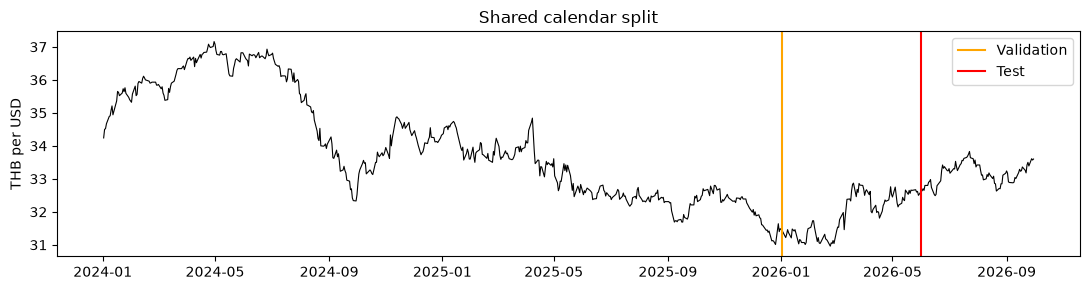

In [5]:
def make_split_indices(n_rows, estimation_window, test_forecasts):
    if (estimation_window < 1 or test_forecasts < 1
            or n_rows <= estimation_window + test_forecasts):
        raise ValueError('Need an initial estimation window, Validation targets and Test targets.')
    test_start = n_rows - test_forecasts
    return np.arange(estimation_window, test_start), np.arange(test_start, n_rows)

def build_origin_schedule(frame, validation, test, estimation_window):
    rows = []
    for split, indices in [('Validation', validation), ('Test', test)]:
        for origin_number, i in enumerate(indices, start=1):
            start = int(i) - estimation_window
            if start < 0 or i >= len(frame):
                raise ValueError('Forecast origin has insufficient history or no actual target.')
            rows.append({'Split': split, 'Origin_number': origin_number,
                'Train_start_row': start + 1, 'Train_end_row': int(i),
                'Train_start_date': frame.iloc[start][DATE_COL],
                'Train_end_date': frame.iloc[i - 1][DATE_COL],
                'Train_start_source_row': int(frame.iloc[start]['Source_data_row']),
                'Train_end_source_row': int(frame.iloc[i - 1]['Source_data_row']),
                'Estimation_observations': int(i)-start,
                'Target_row': int(i) + 1, 'Target_date': frame.iloc[i][DATE_COL],
                'Target_source_row': int(frame.iloc[i]['Source_data_row']),
                'Horizon_observations': 1, 'Actual_USD_THB': frame.iloc[i][PRICE_COL],
                'Previous_USD_THB': frame.iloc[i - 1][PRICE_COL]})
    return pd.DataFrame(rows)



validation_indices,test_indices=make_split_indices(len(df),ESTIMATION_WINDOW,TEST_FORECASTS)
assert (len(validation_indices),len(test_indices))==(103,85)
assert df.iloc[500][DATE_COL]==pd.Timestamp('2025-12-31')
assert df.iloc[501][DATE_COL]==pd.Timestamp('2026-01-02')
assert df.iloc[603][DATE_COL]==pd.Timestamp('2026-05-29')
assert df.iloc[604][DATE_COL]==pd.Timestamp('2026-06-01')
if RUN_MODE not in {'full','smoke'}:raise ValueError('Choose full or smoke')
vi=validation_indices[:2] if RUN_MODE=='smoke' else validation_indices
ti=test_indices[:2] if RUN_MODE=='smoke' else test_indices
schedule=build_origin_schedule(df,vi,ti,ESTIMATION_WINDOW)
assert schedule.Estimation_observations.eq(501).all()
assert (schedule.Train_end_date<schedule.Target_date).all()
split_summary=pd.DataFrame([
    ['Initial Train',501,'2024-01-02','2025-12-31'],
    ['Validation',103,'2026-01-02','2026-05-29'],
    ['Test',85,'2026-06-01','2026-09-30']],columns=['Stage','Observations','Start','End'])
display(split_summary,schedule.head(3),schedule.loc[schedule.Split.eq('Test')].head(3))
fig,ax=plt.subplots(figsize=(11,3))
ax.plot(df[DATE_COL],prices,color='black',linewidth=.8)
ax.axvline(df.iloc[501][DATE_COL],color='orange',label='Validation')
ax.axvline(df.iloc[604][DATE_COL],color='red',label='Test')
ax.set(ylabel='THB per USD',title='Shared calendar split');ax.legend();fig.tight_layout();plt.show()

## Shared training functions

These definitions prepare metrics, lag windows and model implementations; they do not train models yet. Each subsequent model cell performs its own Validation search, locks its settings, then evaluates Test. Candidate results and scaler audits remain in memory as `search_history` and `neural_audits`.

In [6]:
def metrics(actual, predicted, previous):
    actual, predicted, previous = map(np.asarray, (actual, predicted, previous))
    assert actual.shape == predicted.shape == previous.shape
    assert np.isfinite(predicted).all(), 'Invalid forecast.'
    moves = actual - previous
    mask = np.abs(moves) > 1e-12
    da = (100 * np.mean(np.sign(predicted[mask]-previous[mask]) == np.sign(moves[mask]))
          if mask.any() else np.nan)
    true_ret = 100*np.log(actual/previous)
    ret_mae = (mean_absolute_error(true_ret,100*np.log(predicted/previous))
               if (predicted>0).all() else np.nan)
    return {'RMSE': float(np.sqrt(mean_squared_error(actual,predicted))),
            'MAE': float(mean_absolute_error(actual,predicted)),
            'MAPE_pct': float(np.mean(np.abs((actual-predicted)/actual))*100),
            'DA_pct_nonflat': float(da), 'Return_MAE_pctpoints': float(ret_mae)}

def windows(values, indices, lookback):
    values = np.asarray(values)
    indices = np.asarray(indices, dtype=int)
    if values.ndim != 2 or len(indices)==0 or lookback<1 or indices.min()<lookback or indices.max()>=len(values):
        raise ValueError('Need a 2D feature history and valid past-only sample indices.')
    X = np.stack([values[i-lookback:i] for i in indices]).astype(np.float32)
    y = values[indices,0].astype(np.float32)
    return X,y

def evaluate(indices,pred):
    return metrics(prices[indices],np.asarray(pred).reshape(-1),prices[indices-1])

def estimation_values(values, fit_end, estimation_window):
    if estimation_window<1 or fit_end<estimation_window or fit_end>len(values):
        raise ValueError('Invalid estimation boundaries.')
    start = fit_end-estimation_window
    history = np.asarray(values[start:fit_end],dtype=np.float64).copy()
    if not np.isfinite(history).all(): raise ValueError('History must be finite.')
    return history



def train_xgboost(config, fit_end):
    history = estimation_values(features, fit_end, ESTIMATION_WINDOW)
    indices = np.arange(config['lookback'], len(history))
    X, y = windows(history, indices, config['lookback'])
    model = XGBRegressor(objective='reg:squarederror', tree_method='hist',
        n_estimators=config['n_estimators'], max_depth=config['max_depth'],
        learning_rate=config['learning_rate'], random_state=SEED, n_jobs=CPU_THREADS)
    model.fit(X.reshape(len(X), -1), y)
    return model

def predict_xgboost(model, indices, lookback):
    # Do not construct or read the target when building forecast inputs.
    X = np.stack([features[i-lookback:i] for i in indices]).astype(np.float32)
    return model.predict(X.reshape(len(X), -1))

def refit_xgboost(config, indices):
    predictions = []
    model = None
    for i in indices:
        model = train_xgboost(config, int(i))
        predictions.append(float(predict_xgboost(model, np.array([i]), config['lookback'])[0]))
    return np.asarray(predictions), model

class SequenceModel(nn.Module):
    def __init__(self, kind, hidden=32, dropout=0.1):
        super().__init__(); self.kind=kind
        if kind in {'RNN','LSTM'}:
            cls = nn.RNN if kind == 'RNN' else nn.LSTM
            self.encoder = cls(input_size=len(FEATURE_COLS),hidden_size=hidden,num_layers=1,batch_first=True)
        else:
            self.proj = nn.Linear(len(FEATURE_COLS),hidden)
            layer = nn.TransformerEncoderLayer(d_model=hidden,nhead=4,
                dim_feedforward=64,dropout=dropout,batch_first=True)
            self.encoder = nn.TransformerEncoder(layer,num_layers=2)
            position=torch.arange(1024).float().unsqueeze(1)
            div=torch.exp(torch.arange(0,hidden,2).float()*(-np.log(10000.0)/hidden))
            pe=torch.zeros(1024,hidden)
            pe[:,0::2]=torch.sin(position*div); pe[:,1::2]=torch.cos(position*div)
            self.register_buffer('pe',pe.unsqueeze(0))
        self.head=nn.Sequential(nn.Dropout(dropout),nn.Linear(hidden,1))

    def forward(self,x):
        if self.kind in {'RNN','LSTM'}:
            enc,_=self.encoder(x)
        else:
            enc=self.encoder(self.proj(x)+self.pe[:,:x.shape[1]])
        return x[:,-1,0]+self.head(enc[:,-1]).squeeze(-1)

@torch.inference_mode()
def predict_nn(model,X):
    model.eval(); out=[]
    for start in range(0,len(X),256):
        out.append(model(torch.from_numpy(X[start:start+256]).to(DEVICE)).cpu().numpy())
    return np.concatenate(out)

def train_nn(kind, config, fit_end, epochs, checkpoints=()):
    set_seed()
    history = estimation_values(features, fit_end, ESTIMATION_WINDOW)
    lookback = config['lookback']
    if not 1 <= lookback < len(history) or epochs < 1:
        raise ValueError('Need a positive epoch count and input length below the estimation window.')
    checkpoints = set(checkpoints)
    if not checkpoints.issubset(range(1, epochs + 1)):
        raise ValueError('Prediction checkpoints must be within the training epochs.')
    scaler = StandardScaler().fit(history)
    z = scaler.transform(history)
    X, y = windows(z, np.arange(lookback, len(z)), lookback)
    loader = DataLoader(TensorDataset(torch.from_numpy(X), torch.from_numpy(y)),
                        batch_size=BATCH_SIZE, shuffle=True)
    model = SequenceModel(kind).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=config['lr'])
    next_input = z[-lookback:].astype(np.float32)[None, :, :]
    log, checkpoint_predictions = [], {}
    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = nn.functional.mse_loss(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total += loss.item() * len(xb)
        log.append({'epoch': epoch, 'train_mse_scaled': total / len(y)})
        if epoch in checkpoints:
            scaled = predict_nn(model, next_input)
            checkpoint_predictions[epoch] = float(scaled[0] * scaler.scale_[0] + scaler.mean_[0])
    return model, scaler, pd.DataFrame(log), checkpoint_predictions

def refit_nn(kind, config, indices, epoch_options):
    predictions = {int(epoch): [] for epoch in epoch_options}
    audit = []
    for i in tqdm(indices, desc=f'{kind}: Rolling fits', leave=False):
        model, scaler, _, points = train_nn(kind, config, int(i),
            epochs=max(epoch_options), checkpoints=epoch_options)
        for epoch in epoch_options:
            predictions[int(epoch)].append(points[epoch])
        audit.append({'Model': kind, 'Target_row': int(i) + 1,
            'Train_start_row': int(i) - int(scaler.n_samples_seen_) + 1, 'Train_end_row': int(i),
            'Fit_observations': int(scaler.n_samples_seen_),
            'Training_examples': int(scaler.n_samples_seen_) - config['lookback'],
            'Target_scaler_mean': float(scaler.mean_[0]), 'Target_scaler_scale': float(scaler.scale_[0]),
            'Feature_scaler_means': json.dumps(scaler.mean_.tolist()),
            'Feature_scaler_scales': json.dumps(scaler.scale_.tolist()), 'Input_channels': len(FEATURE_COLS),
            'Lookback': config['lookback'], 'Learning_rate': config['lr'],
            'Max_epochs': max(epoch_options)})
        del model
    return {epoch: np.asarray(points) for epoch, points in predictions.items()}, pd.DataFrame(audit)

def recursive_forecast(history, lookback, horizon, predict_one):
    # Only the supplied history and previous predictions enter future windows.
    values = np.asarray(history, dtype=np.float64).copy()
    if (values.ndim != 1 or lookback < 1 or horizon < 1
            or len(values) < lookback or not np.isfinite(values).all()
            or (values <= 0).any()):
        raise ValueError('Provide positive finite history, enough context and a positive horizon.')
    out = []
    for _ in range(horizon):
        value = float(predict_one(values[-lookback:].copy()))
        if not np.isfinite(value) or value <= 0:
            raise ValueError('Future USD/THB forecast must be finite and positive.')
        out.append(value)
        values = np.append(values, value)
    return np.asarray(out)



def result_from_predictions(name, config, validation, test, future=None):
    validation=np.asarray(validation,dtype=float);test=np.asarray(test,dtype=float)
    for points,indices in [(validation,vi),(test,ti)]:
        if len(points)!=len(indices) or not np.isfinite(points).all() or (points<=0).any():
            raise ValueError(f'{name}: invalid predictions')
    group='USD/THB only' if not IS_MULTIVARIATE or name in ['Random Walk','Chronos','TimesFM'] else 'Five historical channels'
    return {'Model':name,'Input_group':group,'Config':dict(config),
            'Validation':evaluate(vi,validation),'Test':evaluate(ti,test),
            'Validation_predictions':validation.copy(),'Test_predictions':test.copy(),
            'Future':future}

def display_result(result):
    print(result['Model'],'| selected using Validation RMSE |',RUN_MODE)
    display(pd.DataFrame([result['Config']]))
    display(pd.DataFrame([{'Split':split,**result[split]} for split in ['Validation','Test']]))

def random_walk_result():
    future=np.repeat(prices[-1],FORECAST_DAYS) if RUN_FUTURE_FORECASTS else None
    return result_from_predictions('Random Walk',{'rule':'last observed level','lookback':1},
                                   prices[vi-1],prices[ti-1],future)

def fit_xgboost_model(candidates):
    candidates=[dict(candidates[0],n_estimators=10)] if RUN_MODE=='smoke' else candidates
    best=np.inf;selected=None;best_points=None;search=[]
    for config in tqdm(candidates,desc='XGBoost: Validation search'):
        points,model=refit_xgboost(config,vi)
        score=evaluate(vi,points);search.append({**config,**score})
        if score['RMSE']<best:
            best=score['RMSE'];selected=dict(config);best_points=points.copy()
        del model
    search_history['XGBoost']=pd.DataFrame(search)
    locked=dict(selected)  # no Test values enter the candidate selection
    test,model=refit_xgboost(locked,ti);del model
    future=None
    if RUN_FUTURE_FORECASTS:
        model=train_xgboost(locked,len(prices))
        future=recursive_forecast(prices[-ESTIMATION_WINDOW:],locked['lookback'],FORECAST_DAYS,
             lambda window:model.predict(window.astype(np.float32)[None,:])[0])
        del model
    return result_from_predictions('XGBoost',locked,best_points,test,future)

def fit_neural_model(kind,candidates,epoch_options):
    candidates=candidates[:1] if RUN_MODE=='smoke' else candidates
    epoch_options=[1] if RUN_MODE=='smoke' else epoch_options
    best=np.inf;selected=None;best_points=None;search=[];audits=[]
    for config in tqdm(candidates,desc=f'{kind}: Validation search'):
        epoch_points,audit=refit_nn(kind,config,vi,epoch_options)
        audit['Split']='Validation';audits.append(audit)
        for epoch,points in epoch_points.items():
            score=evaluate(vi,points);search.append({**config,'epochs':epoch,**score})
            if score['RMSE']<best:
                best=score['RMSE'];selected={**config,'epochs':epoch};best_points=points.copy()
    locked=dict(selected)
    epoch_points,audit=refit_nn(kind,locked,ti,[locked['epochs']])
    audit['Split']='Test';audits.append(audit)
    neural_audits[kind]=pd.concat(audits,ignore_index=True)
    search_history[kind]=pd.DataFrame(search)
    future=None
    if RUN_FUTURE_FORECASTS:
        model,scaler,_,_=train_nn(kind,locked,len(prices),locked['epochs'])
        def predict_point(window):
            z=scaler.transform(window[:,None]).astype(np.float32)
            return float(predict_nn(model,z[None,:,:])[0]*scaler.scale_[0]+scaler.mean_[0])
        future=recursive_forecast(prices[-ESTIMATION_WINDOW:],locked['lookback'],FORECAST_DAYS,predict_point)
        del model
    gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
    return result_from_predictions(kind,locked,best_points,epoch_points[locked['epochs']],future)

def load_timesfm():
    import timesfm
    model=timesfm.TimesFM_2p5_200M_torch.from_pretrained(TIMESFM_ID,revision=TIMESFM_REVISION)
    model.compile(timesfm.ForecastConfig(max_context=max(CONTEXT_OPTIONS),max_horizon=128,
        normalize_inputs=True,per_core_batch_size=FOUNDATION_BATCH,
        use_continuous_quantile_head=False,force_flip_invariance=True,
        infer_is_positive=False,fix_quantile_crossing=True))
    return model

def foundation_points(model,name,indices,context,horizon=1):
    if not 1<=context<=ESTIMATION_WINDOW:
        raise ValueError('Context must fit the allowed history.')
    out=[]
    for start in range(0,len(indices),FOUNDATION_BATCH):
        batch=indices[start:start+FOUNDATION_BATCH]
        histories=[prices[int(i)-context:int(i)].astype(np.float32) for i in batch]
        with torch.inference_mode():
            if name=='Chronos':
                quantiles,_=model.predict_quantiles([torch.tensor(h,dtype=torch.float32) for h in histories],
                                                     prediction_length=horizon,quantile_levels=[.5])
                points=quantiles[:,:,0].cpu().numpy()
            else:
                points,_=model.forecast(horizon=horizon,inputs=histories)
                points=np.asarray(points)[:,:horizon]
        out.extend(points)
    return np.asarray(out)

def fit_foundation_model(name,contexts):
    if name=='Chronos':
        from chronos import BaseChronosPipeline
        model=BaseChronosPipeline.from_pretrained(CHRONOS_ID,device_map=str(DEVICE),
            torch_dtype=torch.float32,revision=CHRONOS_REVISION)
        checkpoint,revision=CHRONOS_ID,CHRONOS_REVISION
    elif name=='TimesFM':
        model=load_timesfm();checkpoint,revision=TIMESFM_ID,TIMESFM_REVISION
    else:raise ValueError('Unknown foundation model')
    best=np.inf;best_context=None;best_points=None;search=[]
    for context in contexts:
        points=foundation_points(model,name,vi,context)[:,0]
        score=evaluate(vi,points);search.append({'context':context,**score})
        if score['RMSE']<best:
            best=score['RMSE'];best_context=int(context);best_points=points.copy()
    locked={'context':best_context,'checkpoint':checkpoint,'revision':revision,'fit':'zero-shot'}
    test=foundation_points(model,name,ti,best_context)[:,0]
    future=foundation_points(model,name,np.array([len(prices)]),best_context,FORECAST_DAYS)[0] if RUN_FUTURE_FORECASTS else None
    del model;gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
    search_history[name]=pd.DataFrame(search)
    return result_from_predictions(name,locked,best_points,test,future)

results={}
search_history={}
neural_audits={}

## Random Walk

**Method:** Use the last observed USD/THB as the next forecast. No fitting or tuning is required.

In [7]:
result = random_walk_result()
results['Random Walk']=result
display_result(result)

Random Walk | selected using Validation RMSE | full


,rule,lookback
0,last observed level,1


,Split,RMSE,MAE,MAPE_pct,DA_pct_nonflat,Return_MAE_pctpoints
0,Validation,0.181736,0.137573,0.430687,0.0,0.430600
1,Test,0.125773,0.100471,0.303000,0.0,0.303089


**Hyperparameters — Random Walk**

- Lookback: 1 observed USD/THB value.
- Drift: none.
- No trainable hyperparameters.

## XGBoost

**Method:** Rolling re-estimation. Train fresh trees on supervised lag samples within each 501-observation history. Choose the candidate with the lowest Validation RMSE, lock it, then refit at each Test origin.

In [8]:
xgb_candidates=[dict(lookback=lb,max_depth=depth,n_estimators=trees,learning_rate=.05)
    for lb in [20,60] for depth in [2,3] for trees in [100,300]]
result = fit_xgboost_model(xgb_candidates)
results['XGBoost']=result
display_result(result)

XGBoost: Validation search: 100%|██████████| 8/8 [01:04<00:00,  8.09s/it]


XGBoost | selected using Validation RMSE | full


,lookback,max_depth,n_estimators,learning_rate
0,20,3,100,0.05


,Split,RMSE,MAE,MAPE_pct,DA_pct_nonflat,Return_MAE_pctpoints
0,Validation,0.197320,0.157963,0.495901,54.455446,0.495728
1,Test,0.148997,0.120614,0.363840,53.658537,0.363986


**Hyperparameters — XGBoost**

- Candidates: lookback 20/60; max depth 2/3; trees 100/300 (8 combinations).
- Learning rate: 0.05; objective: squared error; tree method: hist.
- Seed: 42. XGBoost uses CPU in this implementation.
- Selected settings are displayed in the cell output.

## RNN

**Method:** Rolling re-estimation. Initialize weights and scaler again at every origin. Train each Validation candidate through its largest epoch and score the epoch checkpoints. Lock the best combination, then use that epoch count for every Test refit.

In [9]:
rnn_candidates=[dict(lookback=lb,lr=lr) for lb in [20,60] for lr in [.001,.0003]]
result = fit_neural_model('RNN',rnn_candidates,[5,15])
results['RNN']=result
display_result(result)

RNN: Validation search: 100%|██████████| 4/4 [01:18<00:00, 19.51s/it]


RNN | selected using Validation RMSE | full


,lookback,lr,epochs
0,60,0.0003,5


,Split,RMSE,MAE,MAPE_pct,DA_pct_nonflat,Return_MAE_pctpoints
0,Validation,0.180181,0.136967,0.428721,50.495050,0.428734
1,Test,0.128986,0.105428,0.317828,43.902439,0.318132


**Hyperparameters — RNN**

- Candidates: lookback 20/60; learning rate 0.001/0.0003; epochs 5/15 (8 combinations).
- Hidden size: 32; 1 recurrent layer.
- Dropout: 0.1; Adam; batch size 64; scaled MSE; gradient clipping 1.0.
- StandardScaler: fitted separately inside each 501-observation history.
- Seed: 42; no warm starts or Test-based early stopping.
- Selected settings are displayed in the cell output.

## LSTM

**Method:** Rolling re-estimation. Initialize weights and scaler again at every origin. Train each Validation candidate through its largest epoch and score the epoch checkpoints. Lock the best combination, then use that epoch count for every Test refit.

In [10]:
lstm_candidates=[dict(lookback=lb,lr=lr) for lb in [20,60] for lr in [.001,.0003]]
result = fit_neural_model('LSTM',lstm_candidates,[5,15])
results['LSTM']=result
display_result(result)

LSTM: Validation search: 100%|██████████| 4/4 [03:20<00:00, 50.20s/it]


LSTM | selected using Validation RMSE | full


,lookback,lr,epochs
0,20,0.001,15


,Split,RMSE,MAE,MAPE_pct,DA_pct_nonflat,Return_MAE_pctpoints
0,Validation,0.180985,0.137367,0.430131,50.495050,0.429959
1,Test,0.125295,0.100877,0.304154,56.097561,0.304283


**Hyperparameters — LSTM**

- Candidates: lookback 20/60; learning rate 0.001/0.0003; epochs 5/15 (8 combinations).
- Hidden size: 32; 1 recurrent layer.
- Dropout: 0.1; Adam; batch size 64; scaled MSE; gradient clipping 1.0.
- StandardScaler: fitted separately inside each 501-observation history.
- Seed: 42; no warm starts or Test-based early stopping.
- Selected settings are displayed in the cell output.

## Transformer

**Method:** Rolling re-estimation. Initialize weights and scaler again at every origin. Train each Validation candidate through its largest epoch and score the epoch checkpoints. Lock the best combination, then use that epoch count for every Test refit.

In [11]:
transformer_candidates=[dict(lookback=lb,lr=lr) for lb in [20,60] for lr in [.001,.0003]]
result = fit_neural_model('Transformer',transformer_candidates,[5,15])
results['Transformer']=result
display_result(result)

Transformer: Validation search: 100%|██████████| 4/4 [14:30<00:00, 217.53s/it]


Transformer | selected using Validation RMSE | full


,lookback,lr,epochs
0,20,0.001,15


,Split,RMSE,MAE,MAPE_pct,DA_pct_nonflat,Return_MAE_pctpoints
0,Validation,0.183288,0.138891,0.435226,51.485149,0.434796
1,Test,0.127150,0.102323,0.308735,46.341463,0.308732


**Hyperparameters — Transformer**

- Candidates: lookback 20/60; learning rate 0.001/0.0003; epochs 5/15 (8 combinations).
- Hidden size: 32; 2 encoder layers; 4 attention heads; feedforward size 64; sinusoidal positional encoding.
- Dropout: 0.1; Adam; batch size 64; scaled MSE; gradient clipping 1.0.
- StandardScaler: fitted separately inside each 501-observation history.
- Seed: 42; no warm starts or Test-based early stopping.
- Selected settings are displayed in the cell output.

## Chronos

**Method:** Zero-shot rolling one-step forecasting. Keep pretrained weights fixed and supply only preceding USD/THB values. Select context using Validation RMSE; use the selected context unchanged during Test.

In [12]:
if RUN_FOUNDATION_MODELS:
    result = fit_foundation_model('Chronos',[64,128])
    results['Chronos']=result
    display_result(result)
else:
    print('Chronos','explicitly disabled; no substitute predictions.')

Chronos | selected using Validation RMSE | full


,context,checkpoint,revision,fit
0,128,amazon/chronos-bolt-small,772f3d25d38aec6d914c8949dab4462e2d46f5d8,zero-shot


,Split,RMSE,MAE,MAPE_pct,DA_pct_nonflat,Return_MAE_pctpoints
0,Validation,0.193843,0.149088,0.466259,48.514851,0.466283
1,Test,0.128785,0.102845,0.310244,53.658537,0.310157


**Hyperparameters — Chronos**

- Context candidates: 64/128 USD/THB observations.
- Checkpoint: `amazon/chronos-bolt-small`; pinned revision in configuration.
- One-step prediction: median (q0.5).
- Batch size: 16; no fine-tuning. External pretraining overlap is unverified.
- Selected context is displayed in the cell output.

## TimesFM

**Method:** Zero-shot rolling one-step forecasting. Keep pretrained weights fixed and supply only preceding USD/THB values. Select context using Validation RMSE; use the selected context unchanged during Test.

In [13]:
if RUN_FOUNDATION_MODELS:
    result = fit_foundation_model('TimesFM',[64,128])
    results['TimesFM']=result
    display_result(result)
else:
    print('TimesFM','explicitly disabled; no substitute predictions.')

TimesFM | selected using Validation RMSE | full


,context,checkpoint,revision,fit
0,128,google/timesfm-2.5-200m-pytorch,1d952420fba87f3c6dee4f240de0f1a0fbc790e3,zero-shot


,Split,RMSE,MAE,MAPE_pct,DA_pct_nonflat,Return_MAE_pctpoints
0,Validation,0.186811,0.141461,0.442976,49.504950,0.442906
1,Test,0.133420,0.105032,0.316880,43.902439,0.316968


**Hyperparameters — TimesFM**

- Context candidates: 64/128 USD/THB observations.
- Checkpoint: `google/timesfm-2.5-200m-pytorch`; pinned revision in configuration.
- One-step prediction: point forecast returned by TimesFM.
- Batch size: 16; no fine-tuning. External pretraining overlap is unverified.
- Selected context is displayed in the cell output.

## Model comparison

The selected model is the one with the lowest Validation RMSE. Test RMSE/MAE describe its later performance. A positive Test improvement versus Random Walk means lower error; small differences do not establish statistical significance. Lookback and context shown here are selected settings, not the full candidate grids.

Selected using Validation: RNN | mode: full


,Model,Input_group,Lookback_or_context,Validation_RMSE,Test_RMSE,Test_MAE,Test_MAPE_pct,Test_DA_pct_nonflat,Test_RMSE_improvement_vs_RW_pct,Selected_on_Validation
0,RNN,USD/THB only,60,0.180181,0.128986,0.105428,0.317828,43.902439,-2.554742,True
1,LSTM,USD/THB only,20,0.180985,0.125295,0.100877,0.304154,56.097561,0.380193,False
2,Random Walk,USD/THB only,1,0.181736,0.125773,0.100471,0.303000,0.000000,0.000000,False
3,Transformer,USD/THB only,20,0.183288,0.127150,0.102323,0.308735,46.341463,-1.095040,False
4,TimesFM,USD/THB only,128,0.186811,0.133420,0.105032,0.316880,43.902439,-6.080256,False
5,Chronos,USD/THB only,128,0.193843,0.128785,0.102845,0.310244,53.658537,-2.395057,False
6,XGBoost,USD/THB only,20,0.197320,0.148997,0.120614,0.363840,53.658537,-18.464809,False


,Model,rule,lookback,max_depth,n_estimators,learning_rate,lr,epochs,context,checkpoint,revision,fit
0,Random Walk,last observed level,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,XGBoost,NaN,20.0,3.0,100.0,0.05,NaN,NaN,NaN,NaN,NaN,NaN
2,RNN,NaN,60.0,NaN,NaN,NaN,0.0003,5.0,NaN,NaN,NaN,NaN
3,LSTM,NaN,20.0,NaN,NaN,NaN,0.0010,15.0,NaN,NaN,NaN,NaN
4,Transformer,NaN,20.0,NaN,NaN,NaN,0.0010,15.0,NaN,NaN,NaN,NaN
5,Chronos,NaN,NaN,NaN,NaN,NaN,NaN,NaN,128.0,amazon/chronos-bolt-small,772f3d25d38aec6d914c8949dab4462e2d46f5d8,zero-shot
6,TimesFM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,128.0,google/timesfm-2.5-200m-pytorch,1d952420fba87f3c6dee4f240de0f1a0fbc790e3,zero-shot


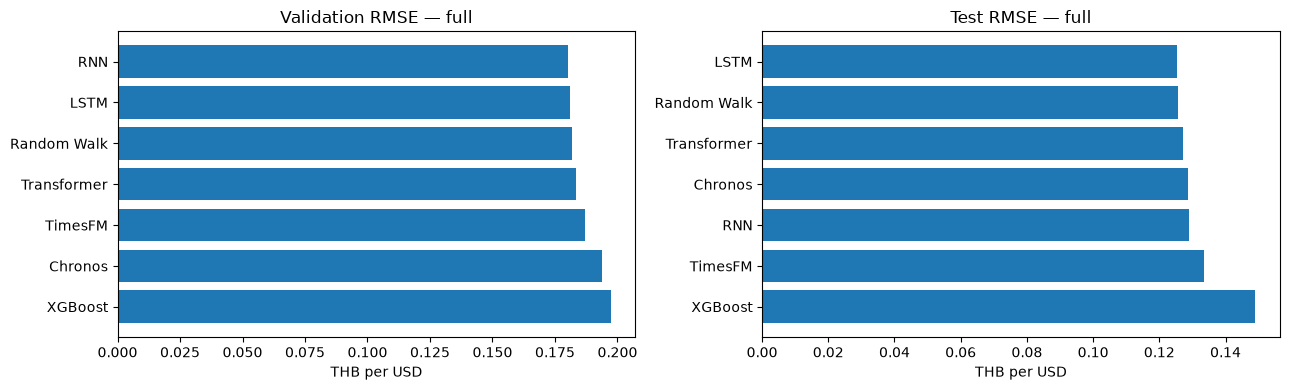

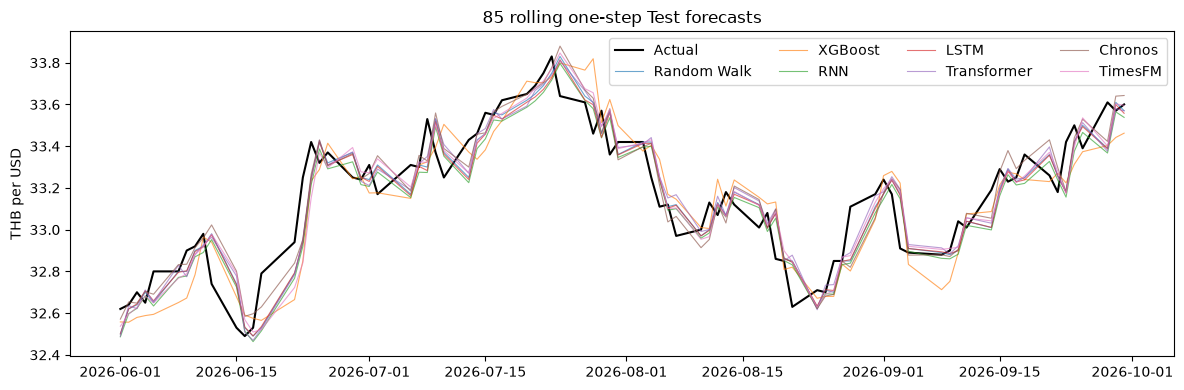

,Date,Actual_USD_THB,Previous_USD_THB,Random Walk,XGBoost,RNN,LSTM,Transformer,Chronos,TimesFM
0,2026-06-01,32.62,32.50,32.50,32.557888,32.486562,32.501194,32.489828,32.571350,32.537292
1,2026-06-02,32.64,32.62,32.62,32.556362,32.597270,32.620676,32.635441,32.653175,32.594681
2,2026-06-03,32.70,32.64,32.64,32.579437,32.623054,32.644047,32.621472,32.648075,32.627712
3,2026-06-04,32.65,32.70,32.70,32.588230,32.682894,32.707497,32.711004,32.703270,32.683052
4,2026-06-05,32.80,32.65,32.65,32.594128,32.634283,32.658970,32.654702,32.690536,32.649673


In [14]:
expected=['Random Walk','XGBoost','RNN','LSTM','Transformer']
if RUN_FOUNDATION_MODELS:expected+=['Chronos','TimesFM']
assert set(results)==set(expected),'Run each enabled model cell before comparison.'
selected_model=min(results,key=lambda name:results[name]['Validation']['RMSE'])
rw_rmse=results['Random Walk']['Test']['RMSE']
comparison_table=pd.DataFrame([{
    'Model':name,'Input_group':results[name]['Input_group'],
    'Lookback_or_context':results[name]['Config'].get('lookback',results[name]['Config'].get('context',1)),
    'Validation_RMSE':results[name]['Validation']['RMSE'],
    'Test_RMSE':results[name]['Test']['RMSE'],'Test_MAE':results[name]['Test']['MAE'],
    'Test_MAPE_pct':results[name]['Test']['MAPE_pct'],
    'Test_DA_pct_nonflat':results[name]['Test']['DA_pct_nonflat'],
    'Test_RMSE_improvement_vs_RW_pct':100*(1-results[name]['Test']['RMSE']/rw_rmse) if rw_rmse>0 else np.nan,
    'Selected_on_Validation':name==selected_model} for name in expected
]).sort_values('Validation_RMSE').reset_index(drop=True)
print('Selected using Validation:',selected_model,'| mode:',RUN_MODE)
if RUN_MODE=='smoke':print('SMOKE CHECK ONLY — reduced search and two targets per split.')
display(comparison_table)
selected_hyperparameters=pd.DataFrame([{'Model':name,**results[name]['Config']} for name in expected])
display(selected_hyperparameters)
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,split in zip(axes,['Validation','Test']):
    ordered=comparison_table.sort_values(f'{split}_RMSE')
    ax.barh(ordered.Model,ordered[f'{split}_RMSE']);ax.invert_yaxis()
    ax.set(title=f'{split} RMSE — {RUN_MODE}',xlabel='THB per USD')
fig.tight_layout();plt.show()
test_predictions=pd.DataFrame({'Date':df.iloc[ti][DATE_COL].to_numpy(),
    'Actual_USD_THB':prices[ti],'Previous_USD_THB':prices[ti-1]})
for name in expected:test_predictions[name]=results[name]['Test_predictions']
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(test_predictions.Date,test_predictions.Actual_USD_THB,color='black',label='Actual',linewidth=1.5)
for name in expected:ax.plot(test_predictions.Date,test_predictions[name],label=name,alpha=.65,linewidth=.8)
ax.set(title=f'{len(ti)} rolling one-step Test forecasts',ylabel='THB per USD')
ax.legend(ncol=4);fig.tight_layout();plt.show()
display(test_predictions.head())

## Five-business-day forecasts

After evaluation, each fitted model is refitted once on the latest 501 actuals using its Validation-selected settings. The model cells already computed five recursive steps without training on predictions; foundation models forecast five steps directly. The origin is **30 September 2026**, not today's date. Dates skip weekends but do not adjust source holidays. No future actuals are supplied for scoring.

,Date,Horizon,Random Walk,XGBoost,RNN,LSTM,Transformer,Chronos,TimesFM,Selected_model,Selected_USD_THB
0,2026-10-01,1,33.6,33.572430,33.564354,33.581486,33.590083,33.683865,33.604145,RNN,33.564354
1,2026-10-02,2,33.6,33.572430,33.529524,33.563166,33.580535,33.686123,33.614079,RNN,33.529524
2,2026-10-05,3,33.6,33.572430,33.496080,33.545309,33.571716,33.677094,33.598885,RNN,33.496080
3,2026-10-06,4,33.6,33.580009,33.463009,33.527979,33.563850,33.688416,33.585537,RNN,33.463009
4,2026-10-07,5,33.6,33.583195,33.432207,33.511164,33.556918,33.692516,33.579765,RNN,33.432207


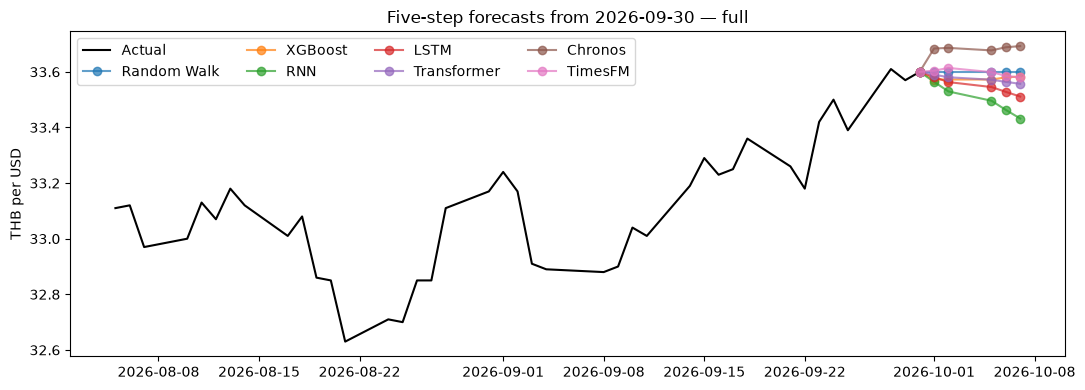

In [15]:
if RUN_FUTURE_FORECASTS:
    origin=pd.Timestamp(df[DATE_COL].iloc[-1])
    dates=pd.bdate_range(origin+pd.offsets.BDay(1),periods=FORECAST_DAYS)
    future_forecast=pd.DataFrame({'Date':dates,'Horizon':np.arange(1,FORECAST_DAYS+1)})
    for name in expected:
        points=np.asarray(results[name]['Future'])
        assert points.shape==(FORECAST_DAYS,) and np.isfinite(points).all() and (points>0).all(),name
        future_forecast[name]=points
    future_forecast['Selected_model']=selected_model
    future_forecast['Selected_USD_THB']=results[selected_model]['Future']
    display(future_forecast)
    fig,ax=plt.subplots(figsize=(11,4))
    ax.plot(df[DATE_COL].iloc[-40:],prices[-40:],color='black',label='Actual')
    for name in expected:
        ax.plot(pd.DatetimeIndex([origin]).append(dates),np.r_[prices[-1],results[name]['Future']],marker='o',label=name,alpha=.7)
    ax.set(title=f'Five-step forecasts from {origin.date()} — {RUN_MODE}',ylabel='THB per USD')
    ax.legend(ncol=4);fig.tight_layout();plt.show()